<a href="https://colab.research.google.com/github/shreyasharma1106/Hospital-Management-System/blob/main/Solar_PV_Defect_Detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# ============================================================
# FINAL PROJECT - BLOCK 1
# Environment + Google Drive + Research Repository
# Solar PV Defect Diagnostic System
# ============================================================

# Install required packages
!pip install -q ultralytics gdown streamlit opencv-python

# Clone authors' research repository
!git clone -q https://github.com/justld/PV-Detector.git


# ============================================================
# IMPORTS
# ============================================================

import os
import sys
import random
import shutil
import json

import numpy as np
import torch

from google.colab import drive
from ultralytics import YOLO


# ============================================================
# GOOGLE DRIVE
# ============================================================

drive.mount("/content/drive")


# ============================================================
# REPRODUCIBILITY
# ============================================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)

DEVICE = 0 if torch.cuda.is_available() else "cpu"


# ============================================================
# PROJECT DIRECTORIES
# ============================================================

# New clean project folder
DRIVE_ROOT = (
    "/content/drive/MyDrive/"
    "Solar_PV_Final_Project"
)

CONFIG_DIR = os.path.join(
    DRIVE_ROOT,
    "configs"
)

MODEL_DIR = os.path.join(
    DRIVE_ROOT,
    "models"
)

RESULTS_DIR = os.path.join(
    DRIVE_ROOT,
    "results"
)

PLOTS_DIR = os.path.join(
    DRIVE_ROOT,
    "plots"
)

DOCS_DIR = os.path.join(
    DRIVE_ROOT,
    "documentation"
)

for directory in [
    DRIVE_ROOT,
    CONFIG_DIR,
    MODEL_DIR,
    RESULTS_DIR,
    PLOTS_DIR,
    DOCS_DIR
]:
    os.makedirs(
        directory,
        exist_ok=True
    )


# ============================================================
# TEMPORARY COLAB WORKSPACE
# ============================================================

WORK_ROOT = "/content/pv_final_project"

RAW_DATA_DIR = os.path.join(
    WORK_ROOT,
    "data",
    "raw"
)

PROCESSED_DATA_DIR = os.path.join(
    WORK_ROOT,
    "data",
    "processed"
)

os.makedirs(
    RAW_DATA_DIR,
    exist_ok=True
)

os.makedirs(
    PROCESSED_DATA_DIR,
    exist_ok=True
)


# ============================================================
# PAPER REPOSITORY
# ============================================================

REPO_DIR = "/content/PV-Detector"

assert os.path.exists(REPO_DIR), \
    "PV-Detector repository was not cloned."


# ============================================================
# EXPERIMENT SETTINGS
# ============================================================

EXPERIMENT_CONFIG = {

    "seed": SEED,

    # Both models get the SAME budget
    "epochs": 20,

    "image_size": 640,

    "batch_size": 8,

    "optimizer": "SGD",

    "learning_rate": 0.01,

    "momentum": 0.937,

    "weight_decay": 0.0005,

    # NEW CLEAN SPLIT
    "train_ratio": 0.70,

    "val_ratio": 0.15,

    "test_ratio": 0.15
}


# Save configuration permanently
EXPERIMENT_CONFIG_PATH = os.path.join(
    CONFIG_DIR,
    "experiment_config.json"
)

with open(
    EXPERIMENT_CONFIG_PATH,
    "w"
) as f:

    json.dump(
        EXPERIMENT_CONFIG,
        f,
        indent=4
    )


# ============================================================
# ENVIRONMENT REPORT
# ============================================================

print("=" * 75)
print("SOLAR PV DEFECT DIAGNOSTICS - FINAL EXPERIMENT")
print("=" * 75)

print("\nPyTorch version:")
print(torch.__version__)

print("\nCUDA available:")
print(torch.cuda.is_available())

if torch.cuda.is_available():

    print("\nGPU:")
    print(
        torch.cuda.get_device_name(0)
    )

print("\nRandom seed:")
print(SEED)

print("\nTraining budget:")
print("Baseline : 20 epochs")
print("Proposed : 20 epochs")

print("\nPlanned dataset split:")
print("Train      : 70%")
print("Validation : 15%")
print("Test       : 15%")

print("\nPersistent project directory:")
print(DRIVE_ROOT)

print("\nPaper repository:")
print(REPO_DIR)

print("\nRepository files:")

for item in sorted(
    os.listdir(REPO_DIR)
):
    print(" -", item)

print("\nExperiment configuration:")
print(EXPERIMENT_CONFIG_PATH)

print("\n" + "=" * 75)
print("BLOCK 1 COMPLETE")
print("=" * 75)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Mounted at /content/drive
SOLAR PV DEFECT DIAGNOSTICS - FINAL EXPERIMENT

PyTorch version:
2.14.1+cu130

CUDA available:
True

GPU:
Tesla T4

Random seed:
42

Training budget:
Baseline : 20 epochs
Proposed : 20 epochs

Planned dataset split:
Train      : 70%
Validation : 15%
Test       : 15%

Persistent project directory:
/content/drive/MyDrive/Solar_PV_Final_Project

Paper repository:
/content/PV-Detector

Repository files:
 - .git
 - README.md
 - modules.py

Experiment configuration:
/content/drive/MyDrive/Solar_PV_Final_Project/configs/experiment_config.json

BLOCK 1 COMPLETE


In [ ]:
# ============================================================
# FINAL PROJECT - BLOCK 2
# Reconstruct Research-Paper Baseline
#
# Baseline:
# YOLOv8s + CCT + Polarized Self-Attention (PSA)
#
# External custom modules:
# https://github.com/justld/PV-Detector
# ============================================================

import os
import sys
import yaml
import torch
import torch.nn as nn

from ultralytics import YOLO
from ultralytics.nn.modules import Conv
import ultralytics.nn.tasks as tasks


print("=" * 75)
print("RECONSTRUCTING PAPER BASELINE ARCHITECTURE")
print("=" * 75)


# ============================================================
# 1. LOAD AUTHORS' CUSTOM MODULES
# ============================================================

if REPO_DIR not in sys.path:
    sys.path.insert(0, REPO_DIR)

import modules

# Authors' CCT implementation expects Ultralytics Conv
modules.Conv = Conv

print("\n✓ Authors' modules.py imported")
print("✓ Ultralytics Conv dependency supplied")


# ============================================================
# 2. ULTRALYTICS COMPATIBILITY WRAPPERS
# ============================================================

class PaperCCT(nn.Module):

    def __init__(self, channels):
        super().__init__()

        self.block = modules.CCT(
            c1=channels,
            c2=channels
        )

    def forward(self, x):
        return self.block(x)


class PaperPSA(nn.Module):

    def __init__(self, channels):
        super().__init__()

        self.block = modules.PolarizedSelfAttention(
            c1=channels,
            c2=channels
        )

    def forward(self, x):
        return self.block(x)


# Register custom classes
tasks.PaperCCT = PaperCCT
tasks.PaperPSA = PaperPSA

print("✓ PaperCCT registered")
print("✓ PaperPSA registered")


# ============================================================
# 3. RECONSTRUCT BASELINE CONFIGURATION
# ============================================================

paper_config = {

    "nc": 12,

    "scales": {
        "s": [0.33, 0.50, 1024]
    },

    "backbone": [

        [-1, 1, "Conv", [64, 3, 2]],

        [-1, 1, "Conv", [128, 3, 2]],

        [-1, 3, "C2f", [128, True]],

        [-1, 1, "Conv", [256, 3, 2]],

        [-1, 6, "C2f", [256, True]],

        [-1, 1, "Conv", [512, 3, 2]],

        [-1, 6, "C2f", [512, True]],

        [-1, 1, "Conv", [1024, 3, 2]],

        [-1, 3, "C2f", [1024, True]],

        [-1, 1, "SPPF", [1024, 5]],

        # Contextual Transformer module
        [-1, 1, "PaperCCT", [512]]
    ],

    "head": [

        [-1, 1, "nn.Upsample",
         [None, 2, "nearest"]],

        [[-1, 6], 1, "Concat", [1]],

        [-1, 3, "C2f", [512]],

        # Polarized Self-Attention
        [-1, 1, "PaperPSA", [256]],


        [-1, 1, "nn.Upsample",
         [None, 2, "nearest"]],

        [[-1, 4], 1, "Concat", [1]],

        [-1, 3, "C2f", [256]],

        # Polarized Self-Attention
        [-1, 1, "PaperPSA", [128]],


        [-1, 1, "Conv", [256, 3, 2]],

        [[-1, 14], 1, "Concat", [1]],

        [-1, 3, "C2f", [512]],

        # Polarized Self-Attention
        [-1, 1, "PaperPSA", [256]],


        [-1, 1, "Conv", [512, 3, 2]],

        [[-1, 10], 1, "Concat", [1]],

        [-1, 3, "C2f", [1024]],

        # Polarized Self-Attention
        [-1, 1, "PaperPSA", [512]],


        [[18, 22, 26], 1, "Detect", ["nc"]]
    ]
}


# ============================================================
# 4. SAVE ARCHITECTURE CONFIG
# ============================================================

PAPER_MODEL_YAML = os.path.join(
    CONFIG_DIR,
    "paper_baseline_architecture.yaml"
)

with open(
    PAPER_MODEL_YAML,
    "w"
) as f:

    yaml.dump(
        paper_config,
        f,
        sort_keys=False
    )

print("\n✓ Architecture configuration saved:")
print(PAPER_MODEL_YAML)


# ============================================================
# 5. CONSTRUCT BASELINE MODEL
# ============================================================

paper_model = YOLO(
    PAPER_MODEL_YAML,
    task="detect"
)

print("\n✓ Paper baseline constructed")

paper_model.info()


# ============================================================
# 6. VERIFY CUSTOM MODULE LOCATIONS
# ============================================================

print("\n" + "=" * 75)
print("CUSTOM PAPER COMPONENTS")
print("=" * 75)

custom_layers = []

for index, layer in enumerate(
    paper_model.model.model
):

    if layer.__class__.__name__ in [
        "PaperCCT",
        "PaperPSA"
    ]:

        custom_layers.append(
            (
                index,
                layer.__class__.__name__
            )
        )

        print(
            f"Layer {index:2d}: "
            f"{layer.__class__.__name__}"
        )


assert len(custom_layers) == 5, \
    "Expected one CCT and four PSA modules."


# ============================================================
# 7. FULL FORWARD-PASS TEST
# ============================================================

device_name = (
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

paper_model.model.to(
    device_name
)

paper_model.model.eval()

dummy_input = torch.randn(
    1,
    3,
    640,
    640,
    device=device_name
)

with torch.no_grad():

    dummy_output = paper_model.model(
        dummy_input
    )

print("\n✓ 640 × 640 forward pass successful")


# ============================================================
# 8. SAVE ARCHITECTURE PROVENANCE
# ============================================================

architecture_provenance = {

    "baseline_name":
        "Reconstructed YOLOv8s + CCT + PSA",

    "base_framework":
        "Ultralytics YOLOv8s",

    "external_repository":
        "https://github.com/justld/PV-Detector",

    "external_components": [
        "CCT",
        "PolarizedSelfAttention"
    ],

    "complete_yaml_released_by_authors":
        False,

    "reconstruction_note":
        (
            "The authors released the custom CCT and PSA "
            "modules but not the complete Ultralytics model "
            "YAML used in this experiment. The architecture "
            "configuration is therefore a reconstruction "
            "using the paper/repository components."
        ),

    "student_experimental_contribution":
        (
            "Rare-Class-Aware Augmentation and controlled "
            "baseline-versus-proposed evaluation."
        )
}


PROVENANCE_FILE = os.path.join(
    DOCS_DIR,
    "architecture_provenance.json"
)

with open(
    PROVENANCE_FILE,
    "w"
) as f:

    json.dump(
        architecture_provenance,
        f,
        indent=4
    )


print("\n✓ Architecture provenance recorded:")
print(PROVENANCE_FILE)


print("\n" + "=" * 75)
print("BLOCK 2 COMPLETE")
print("=" * 75)

print(
    "\nIMPORTANT: CCT and PSA are external research components."
)

print(
    "Our innovation will be evaluated separately through "
    "the rare-class-aware training strategy."
)

RECONSTRUCTING PAPER BASELINE ARCHITECTURE

✓ Authors' modules.py imported
✓ Ultralytics Conv dependency supplied
✓ PaperCCT registered
✓ PaperPSA registered

✓ Architecture configuration saved:
/content/drive/MyDrive/Solar_PV_Final_Project/configs/paper_baseline_architecture.yaml
WARNING ⚠️ no model scale passed. Assuming scale='s'.

✓ Paper baseline constructed
paper_baseline_architecture summary: 187 layers, 12,956,760 parameters, 12,956,744 gradients, 30.9 GFLOPs

CUSTOM PAPER COMPONENTS
Layer 10: PaperCCT
Layer 14: PaperPSA
Layer 18: PaperPSA
Layer 22: PaperPSA
Layer 26: PaperPSA

✓ 640 × 640 forward pass successful

✓ Architecture provenance recorded:
/content/drive/MyDrive/Solar_PV_Final_Project/documentation/architecture_provenance.json

BLOCK 2 COMPLETE

IMPORTANT: CCT and PSA are external research components.
Our innovation will be evaluated separately through the rare-class-aware training strategy.


In [ ]:
# ============================================================
# FINAL PROJECT - BLOCK 3
# Download + Extract + Audit Official PVEL-AD
#
# IMPORTANT:
# No train/val/test split is created in this block.
# First we inspect the complete dataset and official test files.
# ============================================================

import os
import subprocess
import hashlib
import gdown
import xml.etree.ElementTree as ET

from collections import Counter, defaultdict
from PIL import Image


print("=" * 75)
print("PVEL-AD DOWNLOAD AND DATASET AUDIT")
print("=" * 75)


# ============================================================
# 1. DOWNLOAD OFFICIAL DATASET
# ============================================================

PVEL_RAW_DIR = os.path.join(
    RAW_DATA_DIR,
    "PVEL_AD"
)

os.makedirs(
    PVEL_RAW_DIR,
    exist_ok=True
)

PVEL_DRIVE_URL = (
    "https://drive.google.com/drive/folders/"
    "1AMlo433v-torspIxynzx0wXGced8Eo3q"
)

MAIN_ARCHIVE = os.path.join(
    PVEL_RAW_DIR,
    "solar_cell_EL_image.rar"
)

TEST_ARCHIVE = os.path.join(
    PVEL_RAW_DIR,
    "test_annotation.rar"
)


if not os.path.exists(MAIN_ARCHIVE):

    print("\nDownloading official PVEL-AD files...")

    gdown.download_folder(
        url=PVEL_DRIVE_URL,
        output=PVEL_RAW_DIR,
        quiet=False,
        use_cookies=False
    )

else:

    print("\n✓ Main dataset archive already exists.")


print("\nDownloaded archives:")

for archive in [
    MAIN_ARCHIVE,
    TEST_ARCHIVE
]:

    print(
        os.path.basename(archive),
        "->",
        os.path.exists(archive)
    )


# ============================================================
# 2. INSTALL RAR EXTRACTION TOOL
# ============================================================

!apt-get update -qq
!apt-get install -y -qq unrar


# ============================================================
# 3. EXTRACT MAIN DATASET
# ============================================================

MAIN_EXTRACT_DIR = os.path.join(
    PVEL_RAW_DIR,
    "main_extracted"
)

os.makedirs(
    MAIN_EXTRACT_DIR,
    exist_ok=True
)

expected_main = os.path.join(
    MAIN_EXTRACT_DIR,
    "solar_cell_EL_image"
)


if not os.path.exists(expected_main):

    print("\nExtracting main image dataset...")

    subprocess.run(
        [
            "unrar",
            "x",
            "-o+",
            MAIN_ARCHIVE,
            MAIN_EXTRACT_DIR
        ],
        check=True,
        stdout=subprocess.DEVNULL
    )

    print("✓ Main dataset extracted.")

else:

    print("✓ Main dataset already extracted.")


# ============================================================
# 4. EXTRACT OFFICIAL TEST ANNOTATION ARCHIVE
# ============================================================

TEST_EXTRACT_DIR = os.path.join(
    PVEL_RAW_DIR,
    "test_extracted"
)

os.makedirs(
    TEST_EXTRACT_DIR,
    exist_ok=True
)


if os.path.exists(TEST_ARCHIVE):

    # Extract only if folder is empty
    if not os.listdir(TEST_EXTRACT_DIR):

        print("\nExtracting official test annotation archive...")

        subprocess.run(
            [
                "unrar",
                "x",
                "-o+",
                TEST_ARCHIVE,
                TEST_EXTRACT_DIR
            ],
            check=True,
            stdout=subprocess.DEVNULL
        )

        print("✓ Test annotation archive extracted.")

    else:

        print("✓ Test annotation archive already extracted.")

else:

    print(
        "\n⚠ test_annotation.rar was not found."
    )


# ============================================================
# 5. LOCATE MAIN DATASET
# ============================================================

EL2021_ROOT = os.path.join(
    MAIN_EXTRACT_DIR,
    "solar_cell_EL_image",
    "PVELAD",
    "EL2021"
)

TRAINVAL_ROOT = os.path.join(
    EL2021_ROOT,
    "trainval"
)

SOURCE_IMAGES = os.path.join(
    TRAINVAL_ROOT,
    "JPEGImages"
)

SOURCE_ANNOTATIONS = os.path.join(
    TRAINVAL_ROOT,
    "Annotations"
)

CLASS_FILE = os.path.join(
    EL2021_ROOT,
    "annotation_classes.txt"
)


assert os.path.isdir(SOURCE_IMAGES), \
    "Main image directory not found."

assert os.path.isdir(SOURCE_ANNOTATIONS), \
    "Main annotation directory not found."

assert os.path.exists(CLASS_FILE), \
    "Class file not found."


# ============================================================
# 6. READ OFFICIAL CLASS LIST
# ============================================================

with open(
    CLASS_FILE,
    "r",
    encoding="utf-8"
) as f:

    CLASSES = [
        line.strip()
        for line in f
        if line.strip()
    ]


CLASS_TO_ID = {
    name: index
    for index, name in enumerate(CLASSES)
}


print("\nOfficial classes:")

for index, class_name in enumerate(CLASSES):

    print(
        f"{index:2d} -> {class_name}"
    )


# ============================================================
# 7. AUDIT IMAGE / ANNOTATION PAIRS
# ============================================================

image_files = sorted([
    f for f in os.listdir(SOURCE_IMAGES)
    if f.lower().endswith(
        (".jpg", ".jpeg", ".png")
    )
])

annotation_files = sorted([
    f for f in os.listdir(SOURCE_ANNOTATIONS)
    if f.lower().endswith(".xml")
])


image_stems = {
    os.path.splitext(f)[0]
    for f in image_files
}

annotation_stems = {
    os.path.splitext(f)[0]
    for f in annotation_files
}


missing_annotations = (
    image_stems
    - annotation_stems
)

missing_images = (
    annotation_stems
    - image_stems
)


print("\n" + "=" * 75)
print("IMAGE / ANNOTATION AUDIT")
print("=" * 75)

print(
    "Images:",
    len(image_files)
)

print(
    "XML annotations:",
    len(annotation_files)
)

print(
    "Images without XML:",
    len(missing_annotations)
)

print(
    "XML without image:",
    len(missing_images)
)


# ============================================================
# 8. CLASS DISTRIBUTION + BOX VALIDITY
# ============================================================

class_counts = Counter()

images_per_class = Counter()

invalid_boxes = []

image_dimensions = Counter()


for image_name in image_files:

    stem = os.path.splitext(
        image_name
    )[0]

    xml_path = os.path.join(
        SOURCE_ANNOTATIONS,
        stem + ".xml"
    )

    if not os.path.exists(xml_path):
        continue


    tree = ET.parse(
        xml_path
    )

    root = tree.getroot()


    # Image dimensions
    size = root.find("size")

    width = int(
        float(
            size.findtext("width")
        )
    )

    height = int(
        float(
            size.findtext("height")
        )
    )

    image_dimensions[
        (width, height)
    ] += 1


    present_classes = set()


    for obj in root.findall("object"):

        class_name = obj.findtext(
            "name"
        )

        class_counts[
            class_name
        ] += 1

        present_classes.add(
            class_name
        )


        bbox = obj.find(
            "bndbox"
        )

        xmin = float(
            bbox.findtext("xmin")
        )

        ymin = float(
            bbox.findtext("ymin")
        )

        xmax = float(
            bbox.findtext("xmax")
        )

        ymax = float(
            bbox.findtext("ymax")
        )


        if (
            xmin < 0
            or ymin < 0
            or xmax > width
            or ymax > height
            or xmax <= xmin
            or ymax <= ymin
        ):

            invalid_boxes.append({
                "image": image_name,
                "class": class_name,
                "box": [
                    xmin,
                    ymin,
                    xmax,
                    ymax
                ]
            })


    for class_name in present_classes:

        images_per_class[
            class_name
        ] += 1


print("\n" + "=" * 75)
print("CLASS DISTRIBUTION")
print("=" * 75)

print(
    f"{'Class':28s}"
    f"{'Instances':>12s}"
    f"{'Images':>12s}"
)

print("-" * 52)

for class_name in CLASSES:

    print(
        f"{class_name:28s}"
        f"{class_counts[class_name]:12d}"
        f"{images_per_class[class_name]:12d}"
    )


print(
    "\nTotal instances:",
    sum(class_counts.values())
)

print(
    "Invalid bounding boxes:",
    len(invalid_boxes)
)


# ============================================================
# 9. IMAGE DIMENSIONS
# ============================================================

print("\n" + "=" * 75)
print("IMAGE DIMENSIONS")
print("=" * 75)

for dimensions, count in (
    image_dimensions
    .most_common()
):

    print(
        f"{dimensions[0]} x "
        f"{dimensions[1]} : "
        f"{count}"
    )


# ============================================================
# 10. EXACT DUPLICATE IMAGE CHECK
#
# SHA-256 is used to identify byte-identical images.
# This helps demonstrate leakage checking.
# ============================================================

print("\n" + "=" * 75)
print("EXACT DUPLICATE IMAGE CHECK")
print("=" * 75)


def sha256_file(path):

    digest = hashlib.sha256()

    with open(
        path,
        "rb"
    ) as f:

        while True:

            chunk = f.read(
                1024 * 1024
            )

            if not chunk:
                break

            digest.update(
                chunk
            )

    return digest.hexdigest()


hash_groups = defaultdict(
    list
)


for index, image_name in enumerate(
    image_files,
    start=1
):

    image_path = os.path.join(
        SOURCE_IMAGES,
        image_name
    )

    image_hash = sha256_file(
        image_path
    )

    hash_groups[
        image_hash
    ].append(
        image_name
    )


duplicate_groups = {
    image_hash: names
    for image_hash, names
    in hash_groups.items()
    if len(names) > 1
}


duplicate_image_count = sum(
    len(names) - 1
    for names
    in duplicate_groups.values()
)


print(
    "Unique image hashes:",
    len(hash_groups)
)

print(
    "Duplicate groups:",
    len(duplicate_groups)
)

print(
    "Additional duplicate images:",
    duplicate_image_count
)


if duplicate_groups:

    print(
        "\nExample duplicate groups:"
    )

    for names in list(
        duplicate_groups.values()
    )[:10]:

        print(
            " -",
            names
        )


# ============================================================
# 11. INSPECT OFFICIAL TEST ARCHIVE CONTENT
# ============================================================

print("\n" + "=" * 75)
print("OFFICIAL TEST ARCHIVE INSPECTION")
print("=" * 75)


test_file_summary = Counter()

test_paths = []


for root, dirs, files in os.walk(
    TEST_EXTRACT_DIR
):

    for filename in files:

        full_path = os.path.join(
            root,
            filename
        )

        extension = (
            os.path.splitext(
                filename
            )[1]
            .lower()
        )

        test_file_summary[
            extension
        ] += 1

        test_paths.append(
            full_path
        )


print(
    "Total extracted test files:",
    len(test_paths)
)

print("\nFile types:")

for extension, count in (
    test_file_summary
    .most_common()
):

    print(
        f"{extension or '[no extension]':10s}: "
        f"{count}"
    )


print(
    "\nTop-level extracted structure:"
)


for root, dirs, files in os.walk(
    TEST_EXTRACT_DIR
):

    depth = (
        root
        .replace(
            TEST_EXTRACT_DIR,
            ""
        )
        .count(os.sep)
    )

    if depth <= 2:

        indent = (
            "  " * depth
        )

        print(
            f"{indent}"
            f"{os.path.basename(root)}/ "
            f"({len(files)} files)"
        )


# ============================================================
# 12. SAVE DATASET AUDIT
# ============================================================

dataset_audit = {

    "dataset":
        "PVEL-AD",

    "total_images":
        len(image_files),

    "total_annotations":
        len(annotation_files),

    "total_instances":
        sum(class_counts.values()),

    "classes":
        CLASSES,

    "class_instance_counts":
        dict(class_counts),

    "class_image_counts":
        dict(images_per_class),

    "invalid_bounding_boxes":
        len(invalid_boxes),

    "images_without_annotation":
        len(missing_annotations),

    "annotations_without_image":
        len(missing_images),

    "unique_image_hashes":
        len(hash_groups),

    "duplicate_groups":
        len(duplicate_groups),

    "additional_duplicate_images":
        duplicate_image_count,

    "official_test_archive_files":
        len(test_paths),

    "official_test_archive_file_types":
        dict(test_file_summary)
}


DATASET_AUDIT_FILE = os.path.join(
    DOCS_DIR,
    "dataset_audit.json"
)


with open(
    DATASET_AUDIT_FILE,
    "w"
) as f:

    json.dump(
        dataset_audit,
        f,
        indent=4
    )


print("\n✓ Dataset audit saved:")
print(DATASET_AUDIT_FILE)


print("\n" + "=" * 75)
print("BLOCK 3 COMPLETE")
print("=" * 75)

print(
    "\nDo NOT create the train/validation/test split yet."
)

print(
    "First inspect the output above, especially the "
    "official test archive and rare-class counts."
)

PVEL-AD DOWNLOAD AND DATASET AUDIT



Retrieving folder contents


Processing file 1EtteKnLhSFQ3XMCRXt5wKY-lDkIP7299 solar_cell_EL_image.rar
Processing file 1ZiinYTg8vio4k5gC80PtOPb4xt0FovYp test_annotation.rar


Retrieving folder contents completed
Building directory structure
Building directory structure completed
Downloading...
From (original): https://drive.google.com/uc?id=1EtteKnLhSFQ3XMCRXt5wKY-lDkIP7299
From (redirected): https://drive.google.com/uc?id=1EtteKnLhSFQ3XMCRXt5wKY-lDkIP7299&confirm=t&uuid=b70db5db-8091-46ce-9f55-ffca062af4f8
To: /content/pv_final_project/data/raw/PVEL_AD/solar_cell_EL_image.rar
100%|██████████| 4.21G/4.21G [02:18<00:00, 30.3MB/s]
Downloading...
From (original): https://drive.google.com/uc?id=1ZiinYTg8vio4k5gC80PtOPb4xt0FovYp
From (redirected): https://drive.google.com/uc?id=1ZiinYTg8vio4k5gC80PtOPb4xt0FovYp&confirm=t&uuid=3d21ed71-6e1b-4da2-98ca-c00c3428be8d
To: /content/pv_final_project/data/raw/PVEL_AD/test_annotation.rar
100%|██████████| 6.79M/6.79M [00:00<00:00, 35.7MB/s]
Download completed



Downloaded archives:
solar_cell_EL_image.rar -> True
test_annotation.rar -> True
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)

Extracting main image dataset...
✓ Main dataset extracted.

Extracting official test annotation archive...
✓ Test annotation archive extracted.

Official classes:
 0 -> crack
 1 -> finger
 2 -> black_core
 3 -> thick_line
 4 -> star_crack
 5 -> corner
 6 -> fragment
 7 -> scratch
 8 -> horizontal_dislocation
 9 -> vertical_dislocation
10 -> printing_error
11 -> short_circuit

IMAGE / ANNOTATION AUDIT
Images: 4500
XML annotations: 4500
Images without XML: 0
XML without image: 0

CLASS DISTRIBUTION
Class                          Instances      Images
----------------------------------------------------
crack                               1260         969
finger                              2958        1506
black_core    

In [ ]:
# ============================================================
# FINAL PROJECT - BLOCK 4
# Leakage-Safe Train / Validation / Test Split
# ============================================================

import random
import xml.etree.ElementTree as ET
from collections import Counter


# ------------------------------------------------------------
# Extract classes present in each image
# ------------------------------------------------------------

def get_image_classes(image_name):

    stem = os.path.splitext(image_name)[0]

    xml_path = os.path.join(
        SOURCE_ANNOTATIONS,
        stem + ".xml"
    )

    root = ET.parse(xml_path).getroot()

    return {
        obj.findtext("name")
        for obj in root.findall("object")
    }


image_class_sets = {
    image_name: get_image_classes(image_name)
    for image_name in image_files
}


# ------------------------------------------------------------
# Treat exact duplicates as ONE group
# ------------------------------------------------------------

groups = []

for names in hash_groups.values():

    groups.append({
        "images": names,
        "classes": set().union(
            *[
                image_class_sets[name]
                for name in names
            ]
        )
    })


# ------------------------------------------------------------
# Rare classes receive higher allocation priority
# ------------------------------------------------------------

class_image_frequency = Counter()

for group in groups:

    for class_name in group["classes"]:
        class_image_frequency[class_name] += 1


def rarity_score(group):

    return sum(
        1 / class_image_frequency[c]
        for c in group["classes"]
    )


groups.sort(
    key=rarity_score,
    reverse=True
)


# ------------------------------------------------------------
# Target sizes
# ------------------------------------------------------------

total_images = len(image_files)

target_train = int(total_images * 0.70)
target_val = int(total_images * 0.15)

splits = {
    "train": [],
    "val": [],
    "test": []
}

split_classes = {
    "train": Counter(),
    "val": Counter(),
    "test": Counter()
}


rng = random.Random(SEED)


# ------------------------------------------------------------
# Assign duplicate groups
# ------------------------------------------------------------

for group in groups:

    group_size = len(group["images"])

    candidates = []

    for split_name in [
        "train",
        "val",
        "test"
    ]:

        if split_name == "train":
            target = target_train

        elif split_name == "val":
            target = target_val

        else:
            target = (
                total_images
                - target_train
                - target_val
            )


        size_ratio = (
            len(splits[split_name])
            / max(target, 1)
        )


        # Encourage rare classes to appear in every split
        missing_bonus = sum(
            1
            for c in group["classes"]
            if split_classes[split_name][c] == 0
        )


        score = (
            size_ratio
            - (0.20 * missing_bonus)
        )

        candidates.append(
            (
                score,
                rng.random(),
                split_name
            )
        )


    candidates.sort()

    selected_split = (
        candidates[0][2]
    )


    splits[selected_split].extend(
        group["images"]
    )


    for class_name in group["classes"]:

        split_classes[
            selected_split
        ][class_name] += group_size


# ------------------------------------------------------------
# Final split lists
# ------------------------------------------------------------

train_images = sorted(
    splits["train"]
)

val_images = sorted(
    splits["val"]
)

test_images = sorted(
    splits["test"]
)


# ------------------------------------------------------------
# Verify no image overlap
# ------------------------------------------------------------

assert not (
    set(train_images)
    & set(val_images)
)

assert not (
    set(train_images)
    & set(test_images)
)

assert not (
    set(val_images)
    & set(test_images)
)


# ------------------------------------------------------------
# Verify duplicate hashes do not cross splits
# ------------------------------------------------------------

image_to_split = {}

for name in train_images:
    image_to_split[name] = "train"

for name in val_images:
    image_to_split[name] = "val"

for name in test_images:
    image_to_split[name] = "test"


duplicate_leakage = 0

for names in hash_groups.values():

    locations = {
        image_to_split[name]
        for name in names
    }

    if len(locations) > 1:
        duplicate_leakage += 1


assert duplicate_leakage == 0


# ------------------------------------------------------------
# Count actual OBJECT instances per split
# ------------------------------------------------------------

def count_split_instances(file_list):

    counts = Counter()

    for image_name in file_list:

        stem = os.path.splitext(
            image_name
        )[0]

        root = ET.parse(
            os.path.join(
                SOURCE_ANNOTATIONS,
                stem + ".xml"
            )
        ).getroot()

        for obj in root.findall("object"):

            counts[
                obj.findtext("name")
            ] += 1

    return counts


train_counts = count_split_instances(
    train_images
)

val_counts = count_split_instances(
    val_images
)

test_counts = count_split_instances(
    test_images
)


# ------------------------------------------------------------
# Professor-facing summary
# ------------------------------------------------------------

print("=" * 68)
print("LEAKAGE-SAFE DATASET SPLIT")
print("=" * 68)

print(
    f"Train      : {len(train_images)} images"
)

print(
    f"Validation : {len(val_images)} images"
)

print(
    f"Test       : {len(test_images)} images"
)

print("\nExact duplicate leakage: 0")

print("\nClass coverage:")

print(
    f"{'Class':25s}"
    f"{'Train':>8s}"
    f"{'Val':>8s}"
    f"{'Test':>8s}"
)

print("-" * 49)

for class_name in CLASSES:

    print(
        f"{class_name:25s}"
        f"{train_counts[class_name]:8d}"
        f"{val_counts[class_name]:8d}"
        f"{test_counts[class_name]:8d}"
    )


print("\n✓ No image overlap")
print("✓ Exact duplicates kept within the same split")
print("✓ Test partition will remain untouched during training")

LEAKAGE-SAFE DATASET SPLIT
Train      : 3150 images
Validation : 675 images
Test       : 675 images

Exact duplicate leakage: 0

Class coverage:
Class                       Train     Val    Test
-------------------------------------------------
crack                         882     194     184
finger                       2068     426     464
black_core                    718     157     153
thick_line                    682     151     148
star_crack                     93      20      22
corner                          6       2       1
fragment                        5       1       1
scratch                         3       1       1
horizontal_dislocation        558     120     120
vertical_dislocation          101      16      20
printing_error                 16      16       0
short_circuit                 344      74      74

✓ No image overlap
✓ Exact duplicates kept within the same split
✓ Test partition will remain untouched during training


In [ ]:
# ============================================================
# FINAL PROJECT - BLOCK 5
# Build Leakage-Safe YOLO Dataset
# ============================================================

import os
import shutil
import yaml
import json
import xml.etree.ElementTree as ET


# ============================================================
# 1. OUTPUT DATASET
# ============================================================

FINAL_DATASET_DIR = os.path.join(
    PROCESSED_DATA_DIR,
    "PVEL_AD_FINAL"
)

if os.path.exists(FINAL_DATASET_DIR):
    shutil.rmtree(FINAL_DATASET_DIR)


for split in ["train", "val", "test"]:

    os.makedirs(
        os.path.join(
            FINAL_DATASET_DIR,
            "images",
            split
        ),
        exist_ok=True
    )

    os.makedirs(
        os.path.join(
            FINAL_DATASET_DIR,
            "labels",
            split
        ),
        exist_ok=True
    )


# ============================================================
# 2. XML -> YOLO CONVERSION
# ============================================================

def convert_xml_to_yolo(
    xml_path,
    output_path
):

    root = ET.parse(
        xml_path
    ).getroot()

    size = root.find("size")

    width = float(
        size.findtext("width")
    )

    height = float(
        size.findtext("height")
    )

    yolo_lines = []

    for obj in root.findall("object"):

        class_name = obj.findtext("name")

        class_id = CLASS_TO_ID[
            class_name
        ]

        bbox = obj.find("bndbox")

        xmin = float(
            bbox.findtext("xmin")
        )

        ymin = float(
            bbox.findtext("ymin")
        )

        xmax = float(
            bbox.findtext("xmax")
        )

        ymax = float(
            bbox.findtext("ymax")
        )

        x_center = (
            (xmin + xmax) / 2
        ) / width

        y_center = (
            (ymin + ymax) / 2
        ) / height

        box_width = (
            xmax - xmin
        ) / width

        box_height = (
            ymax - ymin
        ) / height

        yolo_lines.append(
            f"{class_id} "
            f"{x_center:.6f} "
            f"{y_center:.6f} "
            f"{box_width:.6f} "
            f"{box_height:.6f}"
        )

    with open(
        output_path,
        "w"
    ) as f:

        f.write(
            "\n".join(yolo_lines)
        )


# ============================================================
# 3. CREATE EACH SPLIT
# ============================================================

def create_split(
    file_list,
    split_name
):

    image_destination = os.path.join(
        FINAL_DATASET_DIR,
        "images",
        split_name
    )

    label_destination = os.path.join(
        FINAL_DATASET_DIR,
        "labels",
        split_name
    )

    for image_name in file_list:

        stem = os.path.splitext(
            image_name
        )[0]

        shutil.copy2(
            os.path.join(
                SOURCE_IMAGES,
                image_name
            ),
            os.path.join(
                image_destination,
                image_name
            )
        )

        convert_xml_to_yolo(
            os.path.join(
                SOURCE_ANNOTATIONS,
                stem + ".xml"
            ),
            os.path.join(
                label_destination,
                stem + ".txt"
            )
        )


create_split(
    train_images,
    "train"
)

create_split(
    val_images,
    "val"
)

create_split(
    test_images,
    "test"
)


# ============================================================
# 4. DATASET YAML
# ============================================================

BASE_DATA_YAML = os.path.join(
    CONFIG_DIR,
    "pvel_final_base.yaml"
)

dataset_config = {

    "path":
        FINAL_DATASET_DIR,

    "train":
        "images/train",

    "val":
        "images/val",

    "test":
        "images/test",

    "nc":
        len(CLASSES),

    "names": {
        i: name
        for i, name
        in enumerate(CLASSES)
    }
}


with open(
    BASE_DATA_YAML,
    "w"
) as f:

    yaml.dump(
        dataset_config,
        f,
        sort_keys=False
    )


# ============================================================
# 5. SAVE SPLIT MANIFEST
# ============================================================

SPLIT_MANIFEST = os.path.join(
    DOCS_DIR,
    "split_manifest.json"
)

manifest = {

    "seed": SEED,

    "strategy":
        "duplicate-group-aware rare-class-prioritized split",

    "train_images":
        train_images,

    "validation_images":
        val_images,

    "test_images":
        test_images,

    "duplicate_leakage":
        0,

    "test_limitations": {
        "printing_error":
            (
                "No printing_error instances occur in the "
                "test partition because the class originates "
                "from only two source images."
            )
    }
}


with open(
    SPLIT_MANIFEST,
    "w"
) as f:

    json.dump(
        manifest,
        f,
        indent=2
    )


# ============================================================
# 6. FINAL VERIFICATION
# ============================================================

split_sizes = {}

for split in [
    "train",
    "val",
    "test"
]:

    image_dir = os.path.join(
        FINAL_DATASET_DIR,
        "images",
        split
    )

    label_dir = os.path.join(
        FINAL_DATASET_DIR,
        "labels",
        split
    )

    image_count = len(
        os.listdir(image_dir)
    )

    label_count = len(
        os.listdir(label_dir)
    )

    assert image_count == label_count

    split_sizes[split] = image_count


print("=" * 65)
print("FINAL DATASET")
print("=" * 65)

print(
    f"Train      : {split_sizes['train']} images"
)

print(
    f"Validation : {split_sizes['val']} images"
)

print(
    f"Test       : {split_sizes['test']} images"
)

print("\nLeakage:")
print("Image overlap       : 0")
print("Exact duplicate leak: 0")

print(
    "\nTest-set limitation: "
    "printing_error has 0 test instances."
)

print("\n✓ Final dataset ready")

FINAL DATASET
Train      : 3150 images
Validation : 675 images
Test       : 675 images

Leakage:
Image overlap       : 0
Exact duplicate leak: 0

Test-set limitation: printing_error has 0 test instances.

✓ Final dataset ready


In [ ]:
# ============================================================
# FINAL PROJECT - BLOCK 6
# Create Common Initialization for Both Experiments
# ============================================================

import os
import torch
from ultralytics import YOLO


# ------------------------------------------------------------
# 1. Build reconstructed architecture
# ------------------------------------------------------------

initial_model = YOLO(
    PAPER_MODEL_YAML,
    task="detect"
)


# ------------------------------------------------------------
# 2. Load pretrained YOLOv8s
# ------------------------------------------------------------

pretrained_model = YOLO(
    "yolov8s.pt"
)


# ------------------------------------------------------------
# 3. Transfer compatible pretrained tensors
# ------------------------------------------------------------

initial_state = (
    initial_model.model.state_dict()
)

pretrained_state = (
    pretrained_model.model.state_dict()
)

compatible_weights = {}

for key, value in pretrained_state.items():

    if (
        key in initial_state
        and
        initial_state[key].shape == value.shape
    ):

        compatible_weights[key] = value


initial_model.model.load_state_dict(
    compatible_weights,
    strict=False
)


# ------------------------------------------------------------
# 4. Save SAME starting state
# ------------------------------------------------------------

COMMON_INITIAL_STATE = os.path.join(
    MODEL_DIR,
    "common_initial_state.pt"
)

torch.save(
    initial_model.model.state_dict(),
    COMMON_INITIAL_STATE
)


# ------------------------------------------------------------
# 5. Summary
# ------------------------------------------------------------

total_tensors = len(
    initial_state
)

transferred_tensors = len(
    compatible_weights
)

transfer_percentage = (
    transferred_tensors
    / total_tensors
    * 100
)


print("=" * 65)
print("COMMON MODEL INITIALIZATION")
print("=" * 65)

print(
    f"Architecture tensors : {total_tensors}"
)

print(
    f"Pretrained tensors   : {transferred_tensors}"
)

print(
    f"Transfer coverage    : {transfer_percentage:.2f}%"
)

print(
    f"Custom/new tensors   : "
    f"{total_tensors - transferred_tensors}"
)

print("\n✓ Common initialization saved")
print(
    "✓ Baseline and proposed model will start "
    "from identical weights"
)

WARNING ⚠️ no model scale passed. Assuming scale='s'.
COMMON MODEL INITIALIZATION
Architecture tensors : 445
Pretrained tensors   : 167
Transfer coverage    : 37.53%
Custom/new tensors   : 278

✓ Common initialization saved
✓ Baseline and proposed model will start from identical weights


In [ ]:
# ============================================================
# FINAL PROJECT - BLOCK 7
# Train Reconstructed Paper Baseline - 20 Epochs
#
# Baseline:
# YOLOv8s + CCT + PSA
# Original training data (NO rare-class-aware augmentation)
# ============================================================

import os
import torch
from ultralytics import YOLO


# ============================================================
# 1. REBUILD BASELINE
# ============================================================

baseline_model = YOLO(
    PAPER_MODEL_YAML,
    task="detect"
)


# ============================================================
# 2. RESTORE COMMON INITIALIZATION
# ============================================================

common_state = torch.load(
    COMMON_INITIAL_STATE,
    map_location="cpu"
)

baseline_model.model.load_state_dict(
    common_state,
    strict=True
)


# ============================================================
# 3. TRAIN BASELINE
# ============================================================

baseline_results = baseline_model.train(

    data=BASE_DATA_YAML,

    # Controlled training budget
    epochs=20,

    imgsz=640,

    batch=8,

    optimizer="SGD",

    lr0=0.01,

    momentum=0.937,

    weight_decay=0.0005,

    # Reproducibility
    seed=SEED,

    deterministic=True,

    # Complete 20 epochs
    patience=20,

    device=DEVICE,

    # Save directly to Drive
    project=RESULTS_DIR,

    name="BASELINE_20E",

    save=True,

    save_period=5,

    plots=True,

    verbose=True
)


# ============================================================
# 4. VERIFY CHECKPOINT
# ============================================================

BASELINE_RUN_DIR = os.path.join(
    RESULTS_DIR,
    "BASELINE_20E"
)

BASELINE_BEST_MODEL = os.path.join(
    BASELINE_RUN_DIR,
    "weights",
    "best.pt"
)

BASELINE_LAST_MODEL = os.path.join(
    BASELINE_RUN_DIR,
    "weights",
    "last.pt"
)


assert os.path.exists(
    BASELINE_BEST_MODEL
)

assert os.path.exists(
    BASELINE_LAST_MODEL
)


print("\n" + "=" * 65)
print("BASELINE TRAINING COMPLETE")
print("=" * 65)

print("Epochs        : 20")
print("Training data : Original")
print("Architecture  : YOLOv8s + CCT + PSA")

print("\n✓ best.pt saved")
print("✓ last.pt saved")

WARNING ⚠️ no model scale passed. Assuming scale='s'.
Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/Solar_PV_Final_Project/configs/pvel_final_base.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/content/drive/MyDrive

In [ ]:
# ============================================================
# FINAL PROJECT - BLOCK 8
# Record Baseline Validation Results + Research Gap
# ============================================================

import os
import json
import pandas as pd
from ultralytics import YOLO


# ------------------------------------------------------------
# Load genuine trained baseline
# ------------------------------------------------------------

BASELINE_BEST_MODEL = os.path.join(
    RESULTS_DIR,
    "BASELINE_20E",
    "weights",
    "best.pt"
)

baseline_best = YOLO(
    BASELINE_BEST_MODEL
)


# ------------------------------------------------------------
# Validation evaluation
# ------------------------------------------------------------

baseline_val = baseline_best.val(
    data=BASE_DATA_YAML,
    split="val",
    imgsz=640,
    batch=8,
    device=DEVICE,
    plots=True,
    project=RESULTS_DIR,
    name="BASELINE_VALIDATION",
    verbose=False
)


# ------------------------------------------------------------
# Overall metrics
# ------------------------------------------------------------

BASELINE_VAL_METRICS = {

    "precision":
        float(baseline_val.box.mp),

    "recall":
        float(baseline_val.box.mr),

    "mAP50":
        float(baseline_val.box.map50),

    "mAP50_95":
        float(baseline_val.box.map)
}


# ------------------------------------------------------------
# Per-class metrics
# ------------------------------------------------------------

class_ids = baseline_val.box.ap_class_index

per_class_rows = []


for result_index, class_id in enumerate(
    class_ids
):

    class_id = int(class_id)

    per_class_rows.append({

        "class":
            baseline_val.names[class_id],

        "precision":
            float(
                baseline_val.box.p[
                    result_index
                ]
            ),

        "recall":
            float(
                baseline_val.box.r[
                    result_index
                ]
            ),

        "mAP50":
            float(
                baseline_val.box.ap50[
                    result_index
                ]
            ),

        "mAP50_95":
            float(
                baseline_val.box.ap[
                    result_index
                ]
            )
    })


baseline_class_df = pd.DataFrame(
    per_class_rows
)


# ------------------------------------------------------------
# Save evidence
# ------------------------------------------------------------

baseline_class_df.to_csv(
    os.path.join(
        RESULTS_DIR,
        "baseline_validation_per_class.csv"
    ),
    index=False
)


with open(
    os.path.join(
        RESULTS_DIR,
        "baseline_validation_metrics.json"
    ),
    "w"
) as f:

    json.dump(
        BASELINE_VAL_METRICS,
        f,
        indent=4
    )


# ------------------------------------------------------------
# Research-gap summary
# ------------------------------------------------------------

zero_recall = baseline_class_df[
    baseline_class_df["recall"] == 0
]["class"].tolist()


print("=" * 65)
print("BASELINE VALIDATION")
print("=" * 65)

print(
    f"Precision : "
    f"{BASELINE_VAL_METRICS['precision']:.3f}"
)

print(
    f"Recall    : "
    f"{BASELINE_VAL_METRICS['recall']:.3f}"
)

print(
    f"mAP@50    : "
    f"{BASELINE_VAL_METRICS['mAP50']:.3f}"
)

print(
    f"mAP@50-95 : "
    f"{BASELINE_VAL_METRICS['mAP50_95']:.3f}"
)


print("\nClasses with zero validation recall:")

for class_name in zero_recall:
    print(" -", class_name)


print(
    "\nResearch gap: the architecture performs strongly "
    "on several common defects but misses multiple "
    "underrepresented defect classes."
)

print(
    "Proposed experiment: retain the same architecture "
    "and modify only the training distribution using "
    "rare-class-aware augmentation."
)

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
paper_baseline_architecture summary (fused): 123 layers, 12,943,928 parameters, 0 gradients, 30.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2054.7±1577.9 MB/s, size: 192.4 KB)
val: Scanning /content/pv_final_project/data/processed/PVEL_AD_FINAL/labels/val.cache... 675 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 675/675 217.8Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 85/85 6.4it/s 13.2s
                   all        675       1178      0.478      0.401       0.42      0.284
Speed: 1.4ms preprocess, 11.7ms inference, 0.0ms loss, 1.5ms postprocess per image
Results saved to /content/drive/MyDrive/Solar_PV_Final_Project/results/BASELINE_VALIDATION
BASELINE VALIDATION
Precision : 0.478
Recall    : 0.401
mAP@50    : 0.420
mAP@50-95 : 0.284

Classes with zero validation recall:
 - corner
 - fragment
 - scratch
 -

In [ ]:
# ============================================================
# FINAL PROJECT - BLOCK 9
# CORRECTED Rare-Class-Aware Training Dataset
#
# Strategy:
# - Augment TRAINING data only
# - Validation and test remain unchanged
# - Target only genuinely rare classes
# - Cap augmentation by source-image count
# ============================================================

import os
import cv2
import shutil
import random
import yaml
from collections import Counter


# ============================================================
# 1. TARGETED AUGMENTATION POLICY
# ============================================================

# Number of additional variants generated per source image.
#
# More augmentation for extremely rare classes,
# moderate augmentation for less rare classes.

RARE_MULTIPLIERS = {

    "scratch": 8,

    "fragment": 6,

    "corner": 6,

    # Only two original source images contain printing_error.
    # Keep this deliberately capped.
    "printing_error": 4,

    "star_crack": 1,

    "vertical_dislocation": 1
}


# ============================================================
# 2. RECREATE PROPOSED DATASET
# ============================================================

RARE_DATASET_DIR = os.path.join(
    PROCESSED_DATA_DIR,
    "PVEL_AD_RARE_AWARE"
)

if os.path.exists(RARE_DATASET_DIR):

    shutil.rmtree(
        RARE_DATASET_DIR
    )


# Start from exact baseline dataset
shutil.copytree(
    FINAL_DATASET_DIR,
    RARE_DATASET_DIR
)


rare_train_images = os.path.join(
    RARE_DATASET_DIR,
    "images",
    "train"
)

rare_train_labels = os.path.join(
    RARE_DATASET_DIR,
    "labels",
    "train"
)


# ============================================================
# 3. IDENTIFY TRAINING IMAGES FOR TARGET CLASSES
# ============================================================

target_class_ids = {

    CLASS_TO_ID[class_name]:
        class_name

    for class_name
    in RARE_MULTIPLIERS
}


class_to_images = {

    class_name: []

    for class_name
    in RARE_MULTIPLIERS
}


for image_name in train_images:

    stem = os.path.splitext(
        image_name
    )[0]

    label_path = os.path.join(
        FINAL_DATASET_DIR,
        "labels",
        "train",
        stem + ".txt"
    )


    with open(
        label_path,
        "r"
    ) as f:

        present_ids = {

            int(line.split()[0])

            for line in f

            if line.strip()
        }


    for class_id, class_name in (
        target_class_ids.items()
    ):

        if class_id in present_ids:

            class_to_images[
                class_name
            ].append(
                image_name
            )


# ============================================================
# 4. AUGMENTATION FUNCTIONS
#
# We use:
#   Variant 0 -> horizontal flip
#   Variant 1 -> vertical flip
#   Variant 2 -> both axes
#   Variant 3+ -> horizontal flip + mild brightness change
#
# Bounding boxes are transformed consistently.
# ============================================================

def read_yolo_labels(
    label_path
):

    labels = []

    with open(
        label_path,
        "r"
    ) as f:

        for line in f:

            parts = line.strip().split()

            if not parts:
                continue

            labels.append([
                int(parts[0]),
                float(parts[1]),
                float(parts[2]),
                float(parts[3]),
                float(parts[4])
            ])

    return labels


def transform_sample(
    image,
    labels,
    variant
):

    transformed_labels = [
        row.copy()
        for row in labels
    ]


    # ---------------------------------------------
    # Horizontal flip
    # ---------------------------------------------

    if variant == 0:

        output_image = cv2.flip(
            image,
            1
        )

        for row in transformed_labels:

            row[1] = (
                1.0 - row[1]
            )


    # ---------------------------------------------
    # Vertical flip
    # ---------------------------------------------

    elif variant == 1:

        output_image = cv2.flip(
            image,
            0
        )

        for row in transformed_labels:

            row[2] = (
                1.0 - row[2]
            )


    # ---------------------------------------------
    # Horizontal + vertical
    # ---------------------------------------------

    elif variant == 2:

        output_image = cv2.flip(
            image,
            -1
        )

        for row in transformed_labels:

            row[1] = (
                1.0 - row[1]
            )

            row[2] = (
                1.0 - row[2]
            )


    # ---------------------------------------------
    # Additional variants:
    # horizontal flip + mild brightness change
    # ---------------------------------------------

    else:

        output_image = cv2.flip(
            image,
            1
        )

        for row in transformed_labels:

            row[1] = (
                1.0 - row[1]
            )


        # Deterministic mild brightness adjustment
        brightness_values = [
            0.90,
            1.10,
            0.85,
            1.15,
            0.95
        ]

        factor = brightness_values[
            (variant - 3)
            % len(brightness_values)
        ]

        output_image = np.clip(
            output_image.astype(
                np.float32
            ) * factor,
            0,
            255
        ).astype(
            np.uint8
        )


    return (
        output_image,
        transformed_labels
    )


# ============================================================
# 5. GENERATE TARGETED AUGMENTATIONS
# ============================================================

augmentation_counts = Counter()

created_source_variant_pairs = set()


for class_name, multiplier in (
    RARE_MULTIPLIERS.items()
):

    source_images = (
        class_to_images[
            class_name
        ]
    )


    for source_name in source_images:

        source_stem = os.path.splitext(
            source_name
        )[0]


        source_image_path = os.path.join(
            FINAL_DATASET_DIR,
            "images",
            "train",
            source_name
        )

        source_label_path = os.path.join(
            FINAL_DATASET_DIR,
            "labels",
            "train",
            source_stem + ".txt"
        )


        image = cv2.imread(
            source_image_path
        )

        labels = read_yolo_labels(
            source_label_path
        )


        for variant in range(
            multiplier
        ):

            # Prevent the same source/variant from being
            # duplicated if an image contains >1 target class.
            pair = (
                source_name,
                variant
            )


            if pair in (
                created_source_variant_pairs
            ):

                continue


            transformed_image, transformed_labels = (
                transform_sample(
                    image,
                    labels,
                    variant
                )
            )


            new_stem = (
                f"rare_aug_"
                f"{source_stem}_"
                f"v{variant}"
            )


            cv2.imwrite(
                os.path.join(
                    rare_train_images,
                    new_stem + ".jpg"
                ),
                transformed_image
            )


            with open(
                os.path.join(
                    rare_train_labels,
                    new_stem + ".txt"
                ),
                "w"
            ) as f:

                for row in (
                    transformed_labels
                ):

                    f.write(

                        f"{row[0]} "
                        f"{row[1]:.6f} "
                        f"{row[2]:.6f} "
                        f"{row[3]:.6f} "
                        f"{row[4]:.6f}\n"
                    )


            created_source_variant_pairs.add(
                pair
            )

            augmentation_counts[
                class_name
            ] += 1


# ============================================================
# 6. COUNT FINAL TRAINING INSTANCES
# ============================================================

def count_yolo_instances(
    label_directory
):

    counts = Counter()

    for filename in os.listdir(
        label_directory
    ):

        if not filename.endswith(
            ".txt"
        ):
            continue


        with open(
            os.path.join(
                label_directory,
                filename
            ),
            "r"
        ) as f:

            for line in f:

                if not line.strip():
                    continue

                class_id = int(
                    line.split()[0]
                )

                counts[
                    CLASSES[class_id]
                ] += 1


    return counts


rare_counts = count_yolo_instances(
    rare_train_labels
)


# ============================================================
# 7. CREATE DATASET CONFIG
# ============================================================

RARE_DATA_YAML = os.path.join(
    CONFIG_DIR,
    "pvel_final_rare_aware.yaml"
)


rare_config = {

    "path":
        RARE_DATASET_DIR,

    "train":
        "images/train",

    "val":
        "images/val",

    "test":
        "images/test",

    "nc":
        len(CLASSES),

    "names": {

        i: name

        for i, name
        in enumerate(CLASSES)
    }
}


with open(
    RARE_DATA_YAML,
    "w"
) as f:

    yaml.dump(
        rare_config,
        f,
        sort_keys=False
    )


# ============================================================
# 8. VERIFY VALIDATION AND TEST ARE UNCHANGED
# ============================================================

for split in [
    "val",
    "test"
]:

    original_images = set(
        os.listdir(
            os.path.join(
                FINAL_DATASET_DIR,
                "images",
                split
            )
        )
    )

    proposed_images = set(
        os.listdir(
            os.path.join(
                RARE_DATASET_DIR,
                "images",
                split
            )
        )
    )


    original_labels = set(
        os.listdir(
            os.path.join(
                FINAL_DATASET_DIR,
                "labels",
                split
            )
        )
    )

    proposed_labels = set(
        os.listdir(
            os.path.join(
                RARE_DATASET_DIR,
                "labels",
                split
            )
        )
    )


    assert (
        original_images
        == proposed_images
    )

    assert (
        original_labels
        == proposed_labels
    )


# ============================================================
# 9. SUMMARY
# ============================================================

original_train_size = len(
    train_images
)

proposed_train_size = len(
    os.listdir(
        rare_train_images
    )
)


print("=" * 68)
print("RARE-CLASS-AWARE TRAINING DATA")
print("=" * 68)

print(
    f"Original training images : "
    f"{original_train_size}"
)

print(
    f"Augmented images         : "
    f"{proposed_train_size - original_train_size}"
)

print(
    f"Proposed training images : "
    f"{proposed_train_size}"
)


print("\nTargeted class distribution:")

print(
    f"{'Class':25s}"
    f"{'Before':>9s}"
    f"{'After':>9s}"
)

print("-" * 43)


for class_name in (
    RARE_MULTIPLIERS
):

    print(
        f"{class_name:25s}"
        f"{train_counts[class_name]:9d}"
        f"{rare_counts[class_name]:9d}"
    )


print("\n✓ Training partition augmented")
print("✓ Validation partition unchanged")
print("✓ Test partition unchanged")

RARE-CLASS-AWARE TRAINING DATA
Original training images : 3150
Augmented images         : 181
Proposed training images : 3331

Targeted class distribution:
Class                       Before    After
-------------------------------------------
scratch                          3       27
fragment                         5       35
corner                           6       42
printing_error                  16       80
star_crack                      93      191
vertical_dislocation           101      202

✓ Training partition augmented
✓ Validation partition unchanged
✓ Test partition unchanged


In [ ]:
# ============================================================
# FINAL PROJECT - BLOCK 10
# Train Proposed Rare-Class-Aware Model - 20 Epochs
#
# Controlled comparison:
# Architecture     : SAME
# Initialization   : SAME
# Optimizer        : SAME
# Hyperparameters  : SAME
# Validation set   : SAME
# Test set         : SAME
#
# Experimental change:
# Rare-Class-Aware Training Augmentation
# ============================================================

import os
import torch
from ultralytics import YOLO


# ============================================================
# 1. BUILD IDENTICAL ARCHITECTURE
# ============================================================

proposed_model = YOLO(
    PAPER_MODEL_YAML,
    task="detect"
)


# ============================================================
# 2. LOAD EXACT SAME INITIALIZATION AS BASELINE
# ============================================================

common_state = torch.load(
    COMMON_INITIAL_STATE,
    map_location="cpu"
)

proposed_model.model.load_state_dict(
    common_state,
    strict=True
)


# ============================================================
# 3. TRAIN PROPOSED MODEL
# ============================================================

proposed_results = proposed_model.train(

    data=RARE_DATA_YAML,

    epochs=20,

    imgsz=640,

    batch=8,

    optimizer="SGD",

    lr0=0.01,

    momentum=0.937,

    weight_decay=0.0005,

    seed=SEED,

    deterministic=True,

    patience=20,

    device=DEVICE,

    project=RESULTS_DIR,

    name="PROPOSED_RARE_AWARE_20E",

    save=True,

    save_period=5,

    plots=True,

    verbose=True
)


# ============================================================
# 4. VERIFY SAVED MODEL
# ============================================================

PROPOSED_RUN_DIR = os.path.join(
    RESULTS_DIR,
    "PROPOSED_RARE_AWARE_20E"
)

PROPOSED_BEST_MODEL = os.path.join(
    PROPOSED_RUN_DIR,
    "weights",
    "best.pt"
)

PROPOSED_LAST_MODEL = os.path.join(
    PROPOSED_RUN_DIR,
    "weights",
    "last.pt"
)


assert os.path.exists(
    PROPOSED_BEST_MODEL
)

assert os.path.exists(
    PROPOSED_LAST_MODEL
)


print("\n" + "=" * 65)
print("PROPOSED MODEL TRAINING COMPLETE")
print("=" * 65)

print("Epochs        : 20")
print("Training data : Rare-Class-Aware")
print("Architecture  : YOLOv8s + CCT + PSA")

print("\n✓ best.pt saved")
print("✓ last.pt saved")

WARNING ⚠️ no model scale passed. Assuming scale='s'.
Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/Solar_PV_Final_Project/configs/pvel_final_rare_aware.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/content/drive/M

In [ ]:
# ============================================================
# FINAL PROJECT - BLOCK 11
# FINAL LOCKED TEST EVALUATION
#
# Both selected best.pt models are evaluated on the SAME
# untouched 675-image test partition.
# ============================================================

import os
import json
import pandas as pd
from ultralytics import YOLO


# ============================================================
# 1. CHECKPOINTS
# ============================================================

BASELINE_BEST_MODEL = os.path.join(
    RESULTS_DIR,
    "BASELINE_20E",
    "weights",
    "best.pt"
)

PROPOSED_BEST_MODEL = os.path.join(
    RESULTS_DIR,
    "PROPOSED_RARE_AWARE_20E",
    "weights",
    "best.pt"
)

assert os.path.exists(BASELINE_BEST_MODEL)
assert os.path.exists(PROPOSED_BEST_MODEL)


# ============================================================
# 2. LOAD MODELS
# ============================================================

baseline_test_model = YOLO(
    BASELINE_BEST_MODEL
)

proposed_test_model = YOLO(
    PROPOSED_BEST_MODEL
)


# ============================================================
# 3. BASELINE TEST
# ============================================================

baseline_test = baseline_test_model.val(

    data=BASE_DATA_YAML,

    split="test",

    imgsz=640,

    batch=8,

    device=DEVICE,

    plots=True,

    project=RESULTS_DIR,

    name="BASELINE_FINAL_TEST",

    verbose=False
)


# ============================================================
# 4. PROPOSED TEST
# ============================================================

proposed_test = proposed_test_model.val(

    data=BASE_DATA_YAML,

    split="test",

    imgsz=640,

    batch=8,

    device=DEVICE,

    plots=True,

    project=RESULTS_DIR,

    name="PROPOSED_FINAL_TEST",

    verbose=False
)


# ============================================================
# 5. OVERALL METRICS
# ============================================================

baseline_metrics = {

    "Precision":
        float(baseline_test.box.mp),

    "Recall":
        float(baseline_test.box.mr),

    "mAP50":
        float(baseline_test.box.map50),

    "mAP50-95":
        float(baseline_test.box.map)
}


proposed_metrics = {

    "Precision":
        float(proposed_test.box.mp),

    "Recall":
        float(proposed_test.box.mr),

    "mAP50":
        float(proposed_test.box.map50),

    "mAP50-95":
        float(proposed_test.box.map)
}


comparison_rows = []


for metric in [
    "Precision",
    "Recall",
    "mAP50",
    "mAP50-95"
]:

    baseline_value = baseline_metrics[
        metric
    ]

    proposed_value = proposed_metrics[
        metric
    ]

    comparison_rows.append({

        "Metric":
            metric,

        "Baseline":
            baseline_value,

        "Proposed":
            proposed_value,

        "Absolute Change":
            proposed_value
            - baseline_value,

        "Relative Change (%)":
            (
                (
                    proposed_value
                    - baseline_value
                )
                / baseline_value
                * 100
            )
            if baseline_value != 0
            else None
    })


comparison_df = pd.DataFrame(
    comparison_rows
)


# ============================================================
# 6. PER-CLASS TEST METRICS
# ============================================================

def extract_per_class(
    metrics,
    prefix
):

    rows = []

    class_indices = (
        metrics.box.ap_class_index
    )


    for result_index, class_id in enumerate(
        class_indices
    ):

        class_id = int(
            class_id
        )

        rows.append({

            "Class":
                metrics.names[
                    class_id
                ],

            f"{prefix} Precision":
                float(
                    metrics.box.p[
                        result_index
                    ]
                ),

            f"{prefix} Recall":
                float(
                    metrics.box.r[
                        result_index
                    ]
                ),

            f"{prefix} mAP50":
                float(
                    metrics.box.ap50[
                        result_index
                    ]
                ),

            f"{prefix} mAP50-95":
                float(
                    metrics.box.ap[
                        result_index
                    ]
                )
        })


    return pd.DataFrame(
        rows
    )


baseline_per_class = extract_per_class(
    baseline_test,
    "Baseline"
)

proposed_per_class = extract_per_class(
    proposed_test,
    "Proposed"
)


per_class_comparison = pd.merge(

    baseline_per_class,

    proposed_per_class,

    on="Class",

    how="outer"
)


per_class_comparison[
    "mAP50 Change"
] = (

    per_class_comparison[
        "Proposed mAP50"
    ]

    - per_class_comparison[
        "Baseline mAP50"
    ]
)


# ============================================================
# 7. SAVE FINAL RESULTS
# ============================================================

FINAL_TEST_JSON = os.path.join(
    RESULTS_DIR,
    "final_test_metrics.json"
)

FINAL_COMPARISON_CSV = os.path.join(
    RESULTS_DIR,
    "final_test_comparison.csv"
)

FINAL_PER_CLASS_CSV = os.path.join(
    RESULTS_DIR,
    "final_test_per_class.csv"
)


with open(
    FINAL_TEST_JSON,
    "w"
) as f:

    json.dump(
        {
            "test_images": 675,

            "baseline":
                baseline_metrics,

            "proposed":
                proposed_metrics,

            "important_limitation":
                (
                    "printing_error has no instances "
                    "in the test partition."
                )
        },
        f,
        indent=4
    )


comparison_df.to_csv(
    FINAL_COMPARISON_CSV,
    index=False
)

per_class_comparison.to_csv(
    FINAL_PER_CLASS_CSV,
    index=False
)


# ============================================================
# 8. PROFESSOR-FACING OUTPUT
# ============================================================

print("=" * 72)
print("FINAL TEST: BASELINE vs PROPOSED")
print("=" * 72)

print(
    comparison_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)


print("\nPer-class mAP@50:")

display_columns = [
    "Class",
    "Baseline mAP50",
    "Proposed mAP50",
    "mAP50 Change"
]

print(
    per_class_comparison[
        display_columns
    ].to_string(
        index=False,
        na_rep="N/A",
        float_format=lambda x: f"{x:.3f}"
    )
)


print(
    "\nTest-set limitation: printing_error has "
    "no test instances and therefore cannot be "
    "evaluated on the final test partition."
)

print(
    "\n✓ Final test evaluation complete"
)

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
paper_baseline_architecture summary (fused): 123 layers, 12,943,928 parameters, 0 gradients, 30.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1445.1±697.3 MB/s, size: 84.5 KB)
val: Scanning /content/pv_final_project/data/processed/PVEL_AD_FINAL/labels/test... 675 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 675/675 1.9Kit/s 0.4s
val: New cache created: /content/pv_final_project/data/processed/PVEL_AD_FINAL/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 85/85 6.7it/s 12.6s
                   all        675       1188      0.441      0.426      0.439      0.307
Speed: 1.2ms preprocess, 11.3ms inference, 0.0ms loss, 1.4ms postprocess per image
Results saved to /content/drive/MyDrive/Solar_PV_Final_Project/results/BASELINE_FINAL_TEST
Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 149

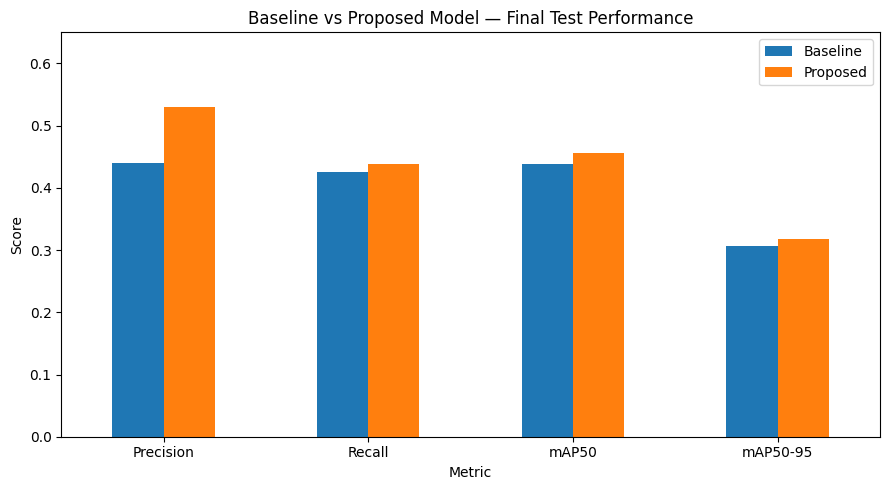

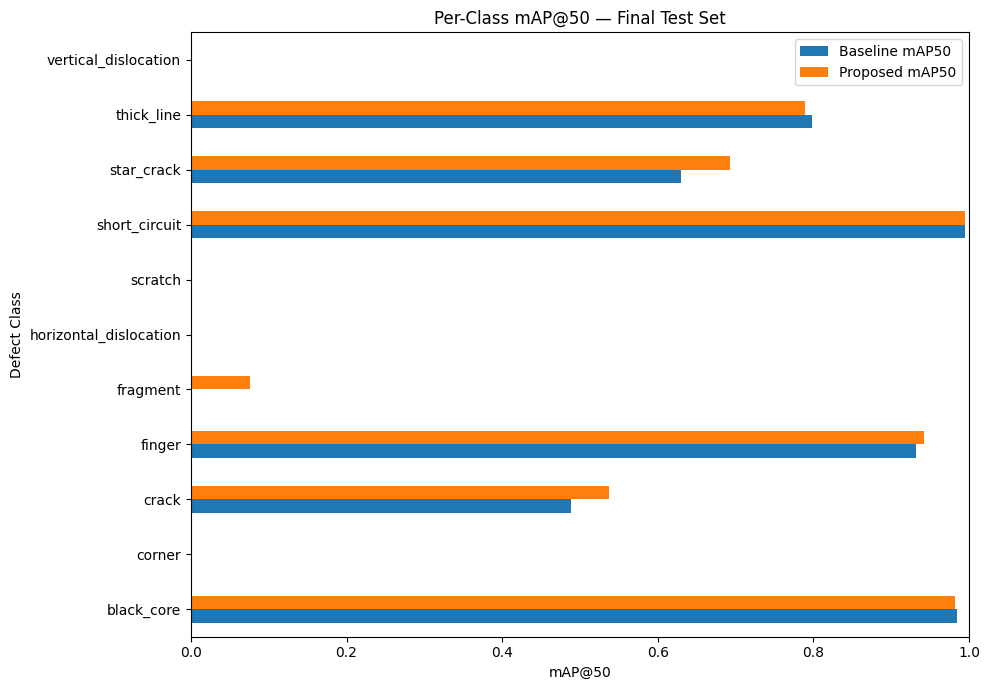

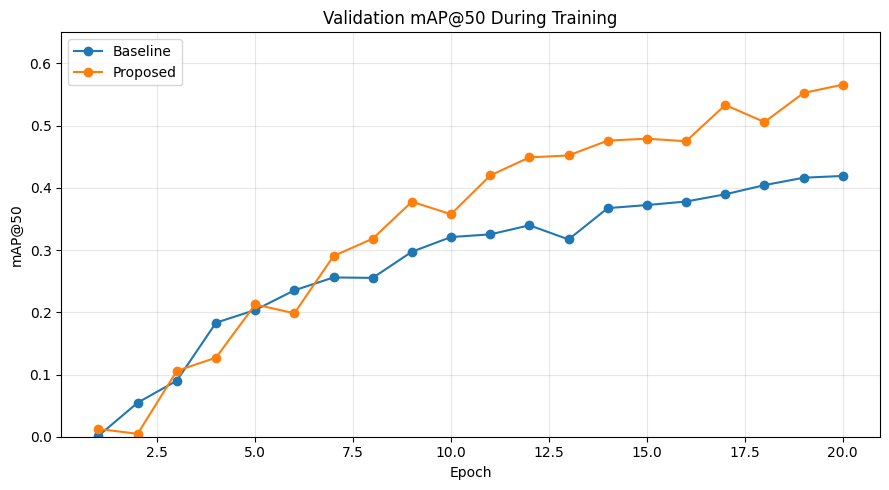

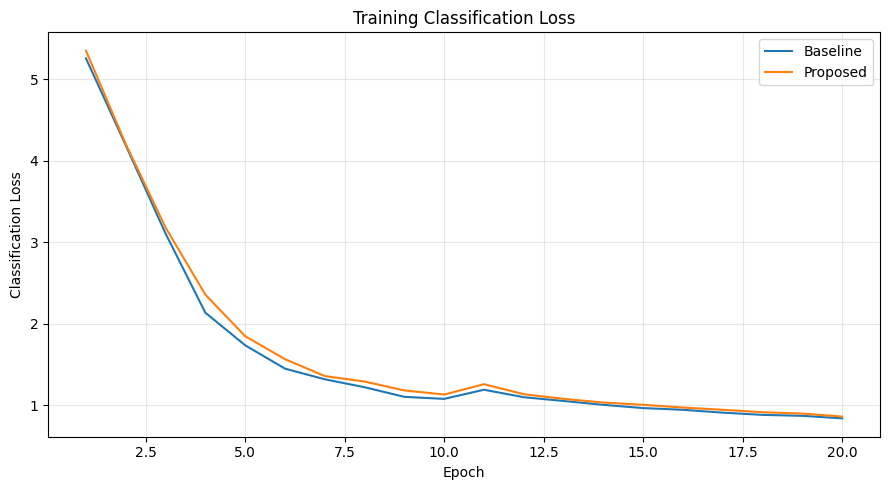

FINAL EXPERIMENT INTERPRETATION
Precision improvement : 20.22%
Recall improvement    : 2.93%
mAP@50 improvement    : 3.87%
mAP@50-95 improvement : 3.25%

The proposed augmentation improved all four aggregate test metrics.
The largest relative improvement was precision.
Per-class gains were mixed; the augmentation did not solve all rare-class detection failures.

✓ Final plots saved to Drive


In [ ]:
# ============================================================
# FINAL PROJECT - BLOCK 12
# Final Comparison + Learning Curves
# ============================================================

import os
import pandas as pd
import matplotlib.pyplot as plt


# ============================================================
# 1. OVERALL TEST COMPARISON
# ============================================================

metrics = [
    "Precision",
    "Recall",
    "mAP50",
    "mAP50-95"
]

baseline_values = [
    baseline_metrics[m]
    for m in metrics
]

proposed_values = [
    proposed_metrics[m]
    for m in metrics
]


comparison_plot_df = pd.DataFrame({
    "Baseline": baseline_values,
    "Proposed": proposed_values
}, index=metrics)


ax = comparison_plot_df.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title(
    "Baseline vs Proposed Model — Final Test Performance"
)

plt.ylabel("Score")
plt.xlabel("Metric")

plt.ylim(0, 0.65)

plt.xticks(
    rotation=0
)

plt.legend()

plt.tight_layout()

OVERALL_PLOT = os.path.join(
    PLOTS_DIR,
    "final_test_comparison.png"
)

plt.savefig(
    OVERALL_PLOT,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 2. PER-CLASS mAP50 COMPARISON
# ============================================================

class_plot = (
    per_class_comparison[
        [
            "Class",
            "Baseline mAP50",
            "Proposed mAP50"
        ]
    ]
    .set_index("Class")
)


class_plot.plot(
    kind="barh",
    figsize=(10, 7)
)

plt.title(
    "Per-Class mAP@50 — Final Test Set"
)

plt.xlabel("mAP@50")
plt.ylabel("Defect Class")

plt.xlim(0, 1)

plt.tight_layout()

CLASS_PLOT = os.path.join(
    PLOTS_DIR,
    "final_per_class_map50.png"
)

plt.savefig(
    CLASS_PLOT,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 3. TRAINING CURVES
# ============================================================

baseline_csv = os.path.join(
    RESULTS_DIR,
    "BASELINE_20E",
    "results.csv"
)

proposed_csv = os.path.join(
    RESULTS_DIR,
    "PROPOSED_RARE_AWARE_20E",
    "results.csv"
)


baseline_history = pd.read_csv(
    baseline_csv
)

proposed_history = pd.read_csv(
    proposed_csv
)

baseline_history.columns = [
    c.strip()
    for c in baseline_history.columns
]

proposed_history.columns = [
    c.strip()
    for c in proposed_history.columns
]


# ------------------------------------------------------------
# mAP50 learning curve
# ------------------------------------------------------------

plt.figure(
    figsize=(9, 5)
)

plt.plot(
    baseline_history["epoch"],
    baseline_history["metrics/mAP50(B)"],
    marker="o",
    label="Baseline"
)

plt.plot(
    proposed_history["epoch"],
    proposed_history["metrics/mAP50(B)"],
    marker="o",
    label="Proposed"
)

plt.title(
    "Validation mAP@50 During Training"
)

plt.xlabel("Epoch")
plt.ylabel("mAP@50")

plt.ylim(0, 0.65)

plt.grid(
    alpha=0.3
)

plt.legend()

plt.tight_layout()

MAP_CURVE = os.path.join(
    PLOTS_DIR,
    "training_map50_comparison.png"
)

plt.savefig(
    MAP_CURVE,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# Training classification loss
# ------------------------------------------------------------

plt.figure(
    figsize=(9, 5)
)

plt.plot(
    baseline_history["epoch"],
    baseline_history["train/cls_loss"],
    label="Baseline"
)

plt.plot(
    proposed_history["epoch"],
    proposed_history["train/cls_loss"],
    label="Proposed"
)

plt.title(
    "Training Classification Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Classification Loss")

plt.grid(
    alpha=0.3
)

plt.legend()

plt.tight_layout()

LOSS_CURVE = os.path.join(
    PLOTS_DIR,
    "training_classification_loss.png"
)

plt.savefig(
    LOSS_CURVE,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 4. FINAL INTERPRETATION
# ============================================================

print("=" * 70)
print("FINAL EXPERIMENT INTERPRETATION")
print("=" * 70)

print(
    "Precision improvement : "
    f"{comparison_df.loc[0, 'Relative Change (%)']:.2f}%"
)

print(
    "Recall improvement    : "
    f"{comparison_df.loc[1, 'Relative Change (%)']:.2f}%"
)

print(
    "mAP@50 improvement    : "
    f"{comparison_df.loc[2, 'Relative Change (%)']:.2f}%"
)

print(
    "mAP@50-95 improvement : "
    f"{comparison_df.loc[3, 'Relative Change (%)']:.2f}%"
)

print(
    "\nThe proposed augmentation improved all four "
    "aggregate test metrics."
)

print(
    "The largest relative improvement was precision."
)

print(
    "Per-class gains were mixed; the augmentation "
    "did not solve all rare-class detection failures."
)

print("\n✓ Final plots saved to Drive")

In [ ]:
# ============================================================
# FINAL PROJECT - BLOCK 13
# Test-Set Error Analysis
# ============================================================

import os
import pandas as pd
import shutil


# ============================================================
# 1. TEST RESULT DIRECTORIES
# ============================================================

BASELINE_TEST_DIR = os.path.join(
    RESULTS_DIR,
    "BASELINE_FINAL_TEST"
)

PROPOSED_TEST_DIR = os.path.join(
    RESULTS_DIR,
    "PROPOSED_FINAL_TEST"
)


# ============================================================
# 2. COPY IMPORTANT CONFUSION MATRICES TO PLOTS FOLDER
# ============================================================

for model_name, source_dir in [
    ("baseline", BASELINE_TEST_DIR),
    ("proposed", PROPOSED_TEST_DIR)
]:

    for plot_name in [
        "confusion_matrix.png",
        "confusion_matrix_normalized.png"
    ]:

        source = os.path.join(
            source_dir,
            plot_name
        )

        if os.path.exists(source):

            destination = os.path.join(
                PLOTS_DIR,
                f"{model_name}_{plot_name}"
            )

            shutil.copy2(
                source,
                destination
            )


# ============================================================
# 3. ADD TEST SUPPORT
# ============================================================

test_support = {
    class_name: test_counts[class_name]
    for class_name in CLASSES
}


analysis_df = (
    per_class_comparison.copy()
)

analysis_df[
    "Test Instances"
] = analysis_df[
    "Class"
].map(
    test_support
)


# ============================================================
# 4. CLASSIFY RESULT BEHAVIOUR
# ============================================================

def classify_change(row):

    baseline = row[
        "Baseline mAP50"
    ]

    proposed = row[
        "Proposed mAP50"
    ]

    support = row[
        "Test Instances"
    ]


    if support == 0:
        return "Not testable"

    if pd.isna(baseline) or pd.isna(proposed):
        return "Not available"

    difference = (
        proposed - baseline
    )

    if difference >= 0.02:
        return "Improved"

    elif difference <= -0.02:
        return "Decreased"

    else:
        return "Approximately unchanged"


analysis_df[
    "Interpretation"
] = analysis_df.apply(
    classify_change,
    axis=1
)


# ============================================================
# 5. SAVE STRUCTURED ERROR ANALYSIS
# ============================================================

ERROR_ANALYSIS_CSV = os.path.join(
    RESULTS_DIR,
    "final_error_analysis.csv"
)

analysis_df.to_csv(
    ERROR_ANALYSIS_CSV,
    index=False
)


# ============================================================
# 6. PROFESSOR-FACING SUMMARY
# ============================================================

print("=" * 72)
print("FINAL TEST ERROR ANALYSIS")
print("=" * 72)

summary_columns = [
    "Class",
    "Test Instances",
    "Baseline mAP50",
    "Proposed mAP50",
    "Interpretation"
]

print(
    analysis_df[
        summary_columns
    ].to_string(
        index=False,
        na_rep="N/A",
        float_format=lambda x: f"{x:.3f}"
    )
)


# ============================================================
# 7. IMPORTANT FINDINGS
# ============================================================

improved = analysis_df[
    analysis_df[
        "Interpretation"
    ] == "Improved"
]["Class"].tolist()


decreased = analysis_df[
    analysis_df[
        "Interpretation"
    ] == "Decreased"
]["Class"].tolist()


zero_proposed = analysis_df[

    (analysis_df[
        "Proposed mAP50"
    ] == 0)

    &

    (analysis_df[
        "Test Instances"
    ] > 0)

]["Class"].tolist()


print("\nImproved classes:")

for class_name in improved:
    print(" +", class_name)


print("\nDecreased classes:")

if decreased:

    for class_name in decreased:
        print(" -", class_name)

else:

    print(" None above the 0.02 threshold")


print("\nStill undetected on test:")

for class_name in zero_proposed:
    print(" !", class_name)


print(
    "\nImportant limitation: printing_error has "
    "no instances in the test partition."
)

print(
    "\nConclusion: rare-class-aware augmentation improved "
    "aggregate generalization and selected defect classes, "
    "but extremely rare and visually difficult defects "
    "remain unresolved."
)

print("\n✓ Error analysis saved")
print("✓ Test confusion matrices preserved")

FINAL TEST ERROR ANALYSIS
                 Class  Test Instances  Baseline mAP50  Proposed mAP50          Interpretation
            black_core             153           0.984           0.982 Approximately unchanged
                corner               1           0.000           0.000 Approximately unchanged
                 crack             184           0.488           0.538                Improved
                finger             464           0.932           0.942 Approximately unchanged
              fragment               1           0.000           0.077                Improved
horizontal_dislocation             120           0.000           0.000 Approximately unchanged
               scratch               1           0.000           0.000 Approximately unchanged
         short_circuit              74           0.995           0.995 Approximately unchanged
            star_crack              22           0.630           0.692                Improved
            thick_line  

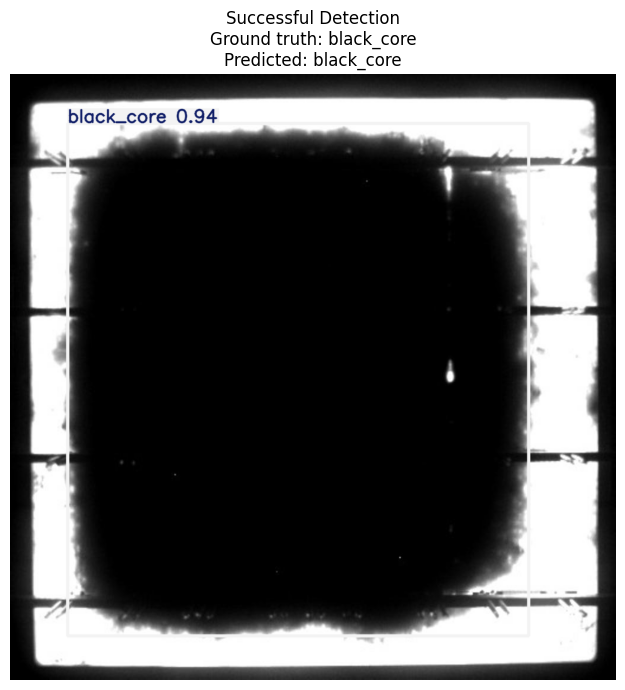

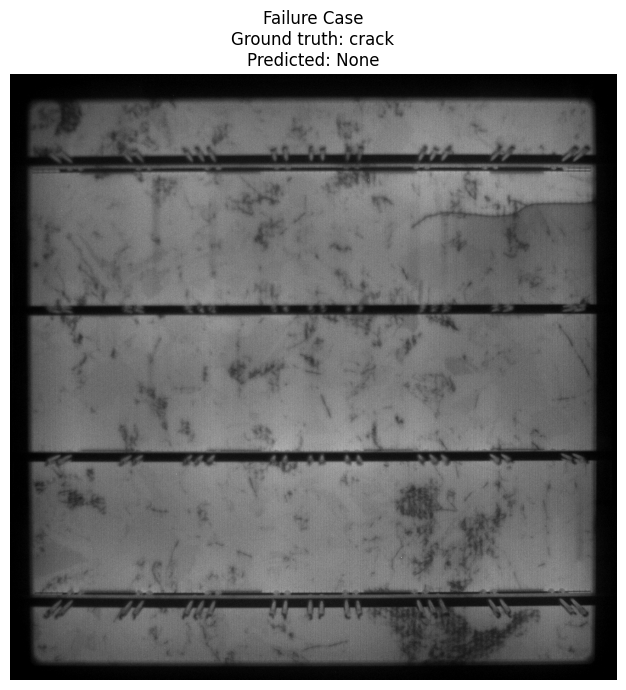

QUALITATIVE TEST ANALYSIS
Successful example : img000007.jpg
Ground truth       : ['black_core']
Predicted          : ['black_core']

Failure example    : img000011.jpg
Ground truth       : ['crack']
Predicted          : []

✓ Representative test examples saved


In [ ]:
# ============================================================
# FINAL PROJECT - BLOCK 14
# Representative Test Predictions and Failure Cases
# ============================================================

import os
import cv2
import shutil
import numpy as np
import matplotlib.pyplot as plt

from ultralytics import YOLO


# ============================================================
# 1. LOAD FINAL PROPOSED MODEL
# ============================================================

final_model = YOLO(
    PROPOSED_BEST_MODEL
)


TEST_IMAGE_DIR = os.path.join(
    FINAL_DATASET_DIR,
    "images",
    "test"
)

TEST_LABEL_DIR = os.path.join(
    FINAL_DATASET_DIR,
    "labels",
    "test"
)


QUALITATIVE_DIR = os.path.join(
    RESULTS_DIR,
    "qualitative_examples"
)

os.makedirs(
    QUALITATIVE_DIR,
    exist_ok=True
)


# ============================================================
# 2. READ GROUND-TRUTH CLASSES
# ============================================================

def get_ground_truth_classes(
    image_name
):

    stem = os.path.splitext(
        image_name
    )[0]

    label_path = os.path.join(
        TEST_LABEL_DIR,
        stem + ".txt"
    )

    classes = set()

    with open(
        label_path,
        "r"
    ) as f:

        for line in f:

            if line.strip():

                class_id = int(
                    line.split()[0]
                )

                classes.add(
                    CLASSES[class_id]
                )

    return classes


# ============================================================
# 3. FIND REPRESENTATIVE CASES
# ============================================================

test_files = sorted([
    f
    for f in os.listdir(TEST_IMAGE_DIR)
    if f.lower().endswith(
        (".jpg", ".jpeg", ".png")
    )
])


success_example = None
failure_example = None


for image_name in test_files:

    image_path = os.path.join(
        TEST_IMAGE_DIR,
        image_name
    )

    ground_truth = get_ground_truth_classes(
        image_name
    )


    prediction = final_model.predict(
        image_path,
        imgsz=640,
        conf=0.25,
        device=DEVICE,
        verbose=False
    )[0]


    predicted_classes = {

        prediction.names[
            int(box.cls[0])
        ]

        for box in prediction.boxes
    }


    # ---------------------------------------------
    # SUCCESS:
    # At least one prediction matches ground truth
    # ---------------------------------------------

    if (
        success_example is None
        and
        ground_truth
        & predicted_classes
    ):

        success_example = (
            image_name,
            prediction,
            ground_truth,
            predicted_classes
        )


    # ---------------------------------------------
    # FAILURE:
    # Ground-truth defect exists but no correct
    # class is detected
    # ---------------------------------------------

    if (
        failure_example is None
        and
        len(ground_truth) > 0
        and
        not (
            ground_truth
            & predicted_classes
        )
    ):

        failure_example = (
            image_name,
            prediction,
            ground_truth,
            predicted_classes
        )


    if (
        success_example is not None
        and
        failure_example is not None
    ):

        break


# ============================================================
# 4. SAVE AND DISPLAY CASE
# ============================================================

def save_case(
    case,
    case_name
):

    if case is None:
        return


    (
        image_name,
        prediction,
        ground_truth,
        predicted_classes
    ) = case


    annotated = prediction.plot()

    annotated_rgb = cv2.cvtColor(
        annotated,
        cv2.COLOR_BGR2RGB
    )


    output_path = os.path.join(
        QUALITATIVE_DIR,
        f"{case_name}.jpg"
    )


    cv2.imwrite(
        output_path,
        annotated
    )


    plt.figure(
        figsize=(7, 7)
    )

    plt.imshow(
        annotated_rgb
    )

    plt.axis(
        "off"
    )

    plt.title(
        f"{case_name.replace('_', ' ').title()}\n"
        f"Ground truth: {', '.join(sorted(ground_truth))}\n"
        f"Predicted: "
        f"{', '.join(sorted(predicted_classes)) if predicted_classes else 'None'}"
    )

    plt.tight_layout()

    plt.show()


    return {
        "image":
            image_name,

        "ground_truth":
            sorted(
                ground_truth
            ),

        "predicted":
            sorted(
                predicted_classes
            ),

        "saved_to":
            output_path
    }


success_info = save_case(
    success_example,
    "successful_detection"
)

failure_info = save_case(
    failure_example,
    "failure_case"
)


# ============================================================
# 5. SUMMARY
# ============================================================

print("=" * 65)
print("QUALITATIVE TEST ANALYSIS")
print("=" * 65)

if success_info:

    print(
        "Successful example :",
        success_info["image"]
    )

    print(
        "Ground truth       :",
        success_info["ground_truth"]
    )

    print(
        "Predicted          :",
        success_info["predicted"]
    )


if failure_info:

    print(
        "\nFailure example    :",
        failure_info["image"]
    )

    print(
        "Ground truth       :",
        failure_info["ground_truth"]
    )

    print(
        "Predicted          :",
        failure_info["predicted"]
    )


print(
    "\n✓ Representative test examples saved"
)

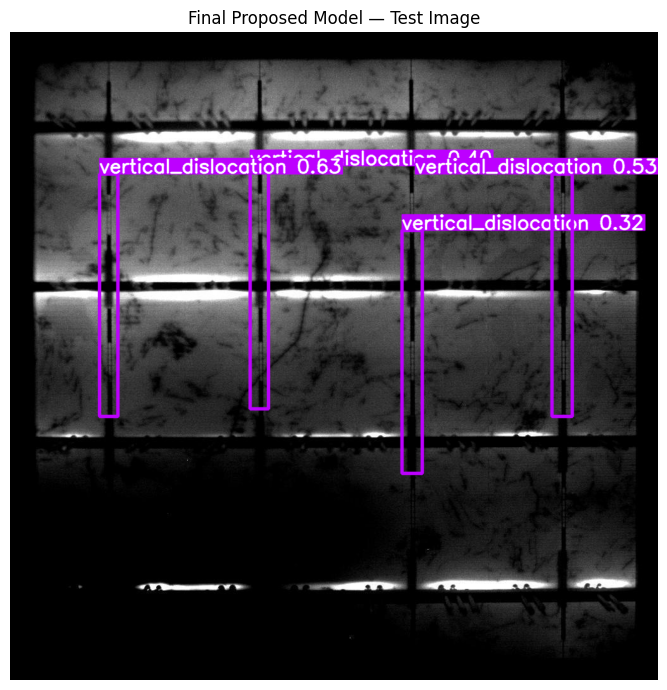

LIVE INFERENCE
Ground truth : vertical_dislocation

Predictions:
 - vertical_dislocation (62.7%)
 - vertical_dislocation (53.5%)
 - vertical_dislocation (39.7%)
 - vertical_dislocation (31.8%)

Inference time: 0.180 s


In [ ]:
# ============================================================
# FINAL PROJECT - BLOCK 15
# Live Test-Set Inference Demonstration
# ============================================================

import os
import random
import time
import cv2
import matplotlib.pyplot as plt

from ultralytics import YOLO


# ------------------------------------------------------------
# Load final proposed model
# ------------------------------------------------------------

demo_model = YOLO(
    PROPOSED_BEST_MODEL
)


# ------------------------------------------------------------
# Select reproducible test image
# ------------------------------------------------------------

demo_rng = random.Random(
    SEED + 100
)

demo_image_name = demo_rng.choice(
    test_files
)

demo_image_path = os.path.join(
    TEST_IMAGE_DIR,
    demo_image_name
)

ground_truth = get_ground_truth_classes(
    demo_image_name
)


# ------------------------------------------------------------
# Inference
# ------------------------------------------------------------

start = time.perf_counter()

demo_result = demo_model.predict(
    demo_image_path,
    imgsz=640,
    conf=0.25,
    device=DEVICE,
    verbose=False
)[0]

elapsed = (
    time.perf_counter()
    - start
)


# ------------------------------------------------------------
# Predictions
# ------------------------------------------------------------

detections = []

for box in demo_result.boxes:

    class_id = int(
        box.cls[0]
    )

    confidence = float(
        box.conf[0]
    )

    detections.append({
        "Defect":
            demo_result.names[
                class_id
            ],

        "Confidence":
            confidence
    })


# ------------------------------------------------------------
# Display annotated image
# ------------------------------------------------------------

annotated = demo_result.plot()

annotated_rgb = cv2.cvtColor(
    annotated,
    cv2.COLOR_BGR2RGB
)

plt.figure(
    figsize=(7, 7)
)

plt.imshow(
    annotated_rgb
)

plt.axis("off")

plt.title(
    "Final Proposed Model — Test Image"
)

plt.tight_layout()

plt.show()


# ------------------------------------------------------------
# Professor-facing output
# ------------------------------------------------------------

print("=" * 60)
print("LIVE INFERENCE")
print("=" * 60)

print(
    "Ground truth :",
    ", ".join(
        sorted(ground_truth)
    )
)

if detections:

    print("\nPredictions:")

    for detection in detections:

        print(
            f" - {detection['Defect']} "
            f"({detection['Confidence'] * 100:.1f}%)"
        )

else:

    print("\nPrediction   : No detection")

print(
    f"\nInference time: {elapsed:.3f} s"
)

In [ ]:
# ============================================================
# FINAL PROJECT - BLOCK 16
# Streamlit Product Interface
# ============================================================

!pip install -q streamlit

import os
import shutil


# ============================================================
# 1. COPY FINAL PROPOSED MODEL FOR UI
# ============================================================

FINAL_MODEL_SOURCE = os.path.join(
    RESULTS_DIR,
    "PROPOSED_RARE_AWARE_20E",
    "weights",
    "best.pt"
)

STREAMLIT_MODEL = "/content/final_pv_model.pt"

assert os.path.exists(FINAL_MODEL_SOURCE)

shutil.copy2(
    FINAL_MODEL_SOURCE,
    STREAMLIT_MODEL
)


# ============================================================
# 2. CREATE STREAMLIT APPLICATION
# ============================================================

app_code = r'''
import os
import sys
import time
import numpy as np
import pandas as pd
import torch.nn as nn
import streamlit as st

from PIL import Image
from ultralytics import YOLO
from ultralytics.nn.modules import Conv
import ultralytics.nn.tasks as tasks


# ============================================================
# CUSTOM MODEL SUPPORT
# ============================================================

REPO_DIR = "/content/PV-Detector"

if REPO_DIR not in sys.path:
    sys.path.insert(0, REPO_DIR)

import modules

modules.Conv = Conv


class PaperCCT(nn.Module):

    def __init__(self, channels):

        super().__init__()

        self.block = modules.CCT(
            c1=channels,
            c2=channels
        )

    def forward(self, x):

        return self.block(x)


class PaperPSA(nn.Module):

    def __init__(self, channels):

        super().__init__()

        self.block = modules.PolarizedSelfAttention(
            c1=channels,
            c2=channels
        )

    def forward(self, x):

        return self.block(x)


tasks.PaperCCT = PaperCCT
tasks.PaperPSA = PaperPSA


# ============================================================
# PAGE CONFIGURATION
# ============================================================

st.set_page_config(
    page_title="PVision | Solar PV Diagnostics",
    page_icon="☀️",
    layout="wide",
    initial_sidebar_state="expanded"
)


# ============================================================
# SIMPLE STYLING
# ============================================================

st.markdown(
    """
    <style>

    .block-container {
        padding-top: 1.5rem;
        padding-bottom: 3rem;
        max-width: 1450px;
    }

    div[data-testid="stMetric"] {
        border: 1px solid rgba(128,128,128,0.20);
        padding: 14px;
        border-radius: 12px;
    }

    div.stButton > button {
        height: 3rem;
        font-weight: 700;
        border-radius: 10px;
    }

    </style>
    """,
    unsafe_allow_html=True
)


# ============================================================
# MODEL
# ============================================================

MODEL_PATH = "/content/final_pv_model.pt"


@st.cache_resource
def load_model():

    return YOLO(
        MODEL_PATH
    )


try:

    model = load_model()
    MODEL_READY = True

except Exception as error:

    MODEL_READY = False

    st.error(
        "Final model could not be loaded."
    )

    st.exception(error)


# ============================================================
# SIDEBAR
# ============================================================

with st.sidebar:

    st.title("☀️ PVision")

    st.caption(
        "Rare-Class-Aware PV Defect Diagnostics"
    )

    st.divider()

    st.subheader(
        "Detection Settings"
    )

    confidence_threshold = st.slider(
        "Confidence threshold",
        min_value=0.10,
        max_value=0.90,
        value=0.25,
        step=0.05
    )

    st.caption(
        "Increasing the threshold produces fewer, "
        "higher-confidence detections."
    )

    st.divider()

    st.subheader(
        "Final Model"
    )

    st.write(
        "**Architecture:** YOLOv8s + CCT + PSA"
    )

    st.write(
        "**Innovation:** Rare-Class-Aware Augmentation"
    )

    st.write(
        "**Dataset:** PVEL-AD"
    )

    st.write(
        "**Training:** 20 epochs"
    )

    st.divider()

    st.subheader(
        "Untouched Test Performance"
    )

    col1, col2 = st.columns(2)

    col1.metric(
        "Precision",
        "52.98%"
    )

    col2.metric(
        "Recall",
        "43.88%"
    )

    col3, col4 = st.columns(2)

    col3.metric(
        "mAP@50",
        "45.59%"
    )

    col4.metric(
        "mAP@50–95",
        "31.73%"
    )

    st.caption(
        "Evaluated on 675 held-out test images."
    )


# ============================================================
# HEADER
# ============================================================

st.title(
    "☀️ Solar PV Defect Diagnostic System"
)

st.subheader(
    "Rare-Class-Aware Photovoltaic Cell Defect Detection"
)

st.write(
    """
    Upload a photovoltaic-cell **electroluminescence (EL)
    image** to detect, classify and localize candidate defects.
    """
)

st.caption(
    "Research prototype • YOLOv8s + CCT + Polarized Self-Attention"
)


# ============================================================
# STATUS
# ============================================================

st.divider()

status1, status2, status3, status4 = st.columns(4)

status1.metric(
    "Model",
    "Ready" if MODEL_READY else "Unavailable"
)

status2.metric(
    "Defect Classes",
    "12"
)

status3.metric(
    "Input",
    "EL Image"
)

status4.metric(
    "Inference Size",
    "640 × 640"
)


# ============================================================
# UPLOAD
# ============================================================

st.divider()

st.header(
    "1. Upload Inspection Image"
)

uploaded_file = st.file_uploader(
    "Choose an EL solar-cell image",
    type=[
        "jpg",
        "jpeg",
        "png"
    ]
)


if uploaded_file is None:

    st.info(
        "Upload an EL image to begin the inspection."
    )


else:

    image = Image.open(
        uploaded_file
    ).convert("RGB")


    # ========================================================
    # PREVIEW
    # ========================================================

    st.header(
        "2. Inspection Preview"
    )

    left, right = st.columns(
        [1.5, 1]
    )


    with left:

        st.image(
            image,
            caption="Uploaded EL image",
            use_container_width=True
        )


    with right:

        st.subheader(
            "Image Information"
        )

        st.write(
            f"**Filename:** {uploaded_file.name}"
        )

        st.write(
            f"**Resolution:** "
            f"{image.width} × {image.height}"
        )

        st.write(
            f"**Confidence threshold:** "
            f"{confidence_threshold:.2f}"
        )

        if MODEL_READY:

            st.success(
                "Final model ready"
            )

        analyse = st.button(
            "🔍 Run Defect Analysis",
            type="primary",
            use_container_width=True
        )


    # ========================================================
    # INFERENCE
    # ========================================================

    if analyse and MODEL_READY:

        with st.spinner(
            "Analysing photovoltaic cell..."
        ):

            start = time.perf_counter()

            results = model.predict(
                source=np.array(image),
                imgsz=640,
                conf=confidence_threshold,
                verbose=False
            )

            elapsed = (
                time.perf_counter()
                - start
            )


        result = results[0]

        detection_count = len(
            result.boxes
        )

        annotated = result.plot()

        annotated = (
            annotated[:, :, ::-1]
        )


        # ====================================================
        # RESULT
        # ====================================================

        st.divider()

        st.header(
            "3. Diagnostic Result"
        )


        if detection_count > 0:

            st.warning(
                "⚠️ Attention Required — "
                f"{detection_count} candidate defect "
                "region(s) detected."
            )

        else:

            st.success(
                "No defect detected above the "
                "selected confidence threshold."
            )


        result_left, result_right = st.columns(
            [1.5, 1]
        )


        with result_left:

            st.image(
                annotated,
                caption="Model detection output",
                use_container_width=True
            )


        with result_right:

            st.subheader(
                "Inspection Summary"
            )

            a, b = st.columns(2)

            a.metric(
                "Detections",
                detection_count
            )

            b.metric(
                "Inference Time",
                f"{elapsed:.3f}s"
            )


            c, d = st.columns(2)

            c.metric(
                "Threshold",
                f"{confidence_threshold:.2f}"
            )


            if detection_count:

                highest = max(
                    float(box.conf[0])
                    for box in result.boxes
                )

                d.metric(
                    "Highest Confidence",
                    f"{highest * 100:.1f}%"
                )

            else:

                d.metric(
                    "Highest Confidence",
                    "—"
                )


        # ====================================================
        # DETECTION TABLE
        # ====================================================

        if detection_count > 0:

            st.header(
                "4. Detected Defects"
            )

            rows = []


            for index, box in enumerate(
                result.boxes,
                start=1
            ):

                class_id = int(
                    box.cls[0]
                )

                confidence = float(
                    box.conf[0]
                )

                class_name = (
                    result.names[
                        class_id
                    ]
                )

                x1, y1, x2, y2 = (
                    box.xyxy[0]
                    .cpu()
                    .tolist()
                )


                rows.append({

                    "ID":
                        index,

                    "Defect":
                        class_name
                        .replace("_", " ")
                        .title(),

                    "Confidence":
                        f"{confidence * 100:.2f}%",

                    "Bounding Box":
                        (
                            f"({x1:.0f}, {y1:.0f}) → "
                            f"({x2:.0f}, {y2:.0f})"
                        )
                })


            detection_df = pd.DataFrame(
                rows
            )


            st.dataframe(
                detection_df,
                use_container_width=True,
                hide_index=True
            )


            st.subheader(
                "Detection Confidence"
            )


            for _, row in (
                detection_df.iterrows()
            ):

                confidence_value = float(
                    row["Confidence"]
                    .replace("%", "")
                )

                st.write(
                    f"**{row['Defect']}** — "
                    f"{row['Confidence']}"
                )

                st.progress(
                    min(
                        int(confidence_value),
                        100
                    )
                )


            csv_report = (
                detection_df
                .to_csv(index=False)
                .encode("utf-8")
            )


            st.download_button(
                "⬇️ Download Detection Report",
                data=csv_report,
                file_name="pv_defect_report.csv",
                mime="text/csv",
                use_container_width=True
            )


        # ====================================================
        # INTERPRETATION
        # ====================================================

        st.header(
            "5. Interpretation"
        )


        if detection_count:

            st.write(
                """
                Bounding boxes indicate candidate defect
                regions. Confidence represents the model's
                certainty for each predicted class.
                """
            )

            st.info(
                "The output should support, not replace, "
                "expert photovoltaic-cell inspection."
            )

        else:

            st.write(
                """
                No prediction exceeded the selected threshold.
                This does not guarantee that the cell is
                defect-free because low-confidence or unseen
                defect patterns may still be present.
                """
            )


# ============================================================
# RESEARCH EVIDENCE
# ============================================================

st.divider()

with st.expander(
    "📊 Research Evidence"
):

    st.subheader(
        "Controlled Test Comparison"
    )

    comparison = pd.DataFrame({

        "Metric": [
            "Precision",
            "Recall",
            "mAP@50",
            "mAP@50–95"
        ],

        "Baseline": [
            0.4407,
            0.4263,
            0.4389,
            0.3073
        ],

        "Proposed": [
            0.5298,
            0.4388,
            0.4559,
            0.3173
        ]
    })

    st.dataframe(
        comparison,
        use_container_width=True,
        hide_index=True
    )


    st.write(
        """
        Both models used the same architecture, initialization,
        data split, optimizer, learning rate, batch size,
        image resolution, random seed and 20-epoch budget.

        The primary experimental change was targeted
        rare-class-aware augmentation of the training
        partition.
        """
    )


    st.subheader(
        "Observed Outcome"
    )

    st.write(
        """
        The proposed strategy improved all four aggregate
        test metrics. The largest relative improvement was
        precision (+20.22%).

        Per-class effects were mixed. Crack, fragment and
        star-crack improved, while several extremely rare or
        difficult classes remained unreliable.
        """
    )


# ============================================================
# LIMITATIONS
# ============================================================

with st.expander(
    "⚠️ Limitations & Responsible Use"
):

    st.write(
        """
        - `printing_error` has no instances in the final test
          partition and therefore has no final test estimate.

        - Corner and scratch each have only one test instance,
          making their class-level estimates unstable.

        - Horizontal and vertical dislocation remain difficult
          for the model at the aggregate class level.

        - Augmentation creates transformed observations but
          does not create genuinely new defect morphology.

        - This application is a research prototype and is not
          intended to replace professional photovoltaic
          inspection or safety decisions.
        """
    )


# ============================================================
# FOOTER
# ============================================================

st.divider()

st.caption(
    "PVision • Solar PV Defect Diagnostic Research Prototype"
)

st.caption(
    "PVEL-AD • YOLOv8s + CCT + PSA • Rare-Class-Aware Augmentation"
)
'''


APP_PATH = os.path.join(
    DRIVE_ROOT,
    "app.py"
)

with open(
    APP_PATH,
    "w"
) as f:

    f.write(
        app_code
    )


# Local copy for execution
shutil.copy2(
    APP_PATH,
    "/content/app.py"
)


print("=" * 65)
print("FINAL PRODUCT INTERFACE")
print("=" * 65)

print("✓ Final proposed model connected")
print("✓ Genuine test metrics integrated")
print("✓ Streamlit application saved to Drive")

FINAL PRODUCT INTERFACE
✓ Final proposed model connected
✓ Genuine test metrics integrated
✓ Streamlit application saved to Drive


In [ ]:
import subprocess
import time
import requests

!pkill -f streamlit 2>/dev/null || true
!pkill -f cloudflared 2>/dev/null || true

process = subprocess.Popen(
    [
        "streamlit",
        "run",
        "/content/app.py",
        "--server.port", "8501",
        "--server.address", "0.0.0.0",
        "--server.headless", "true"
    ],
    stdout=subprocess.DEVNULL,
    stderr=subprocess.DEVNULL
)

time.sleep(7)

response = requests.get(
    "http://127.0.0.1:8501",
    timeout=10
)

print(
    "✓ UI ready"
    if response.status_code == 200
    else "UI startup failed"
)

^C
^C
✓ UI ready


In [ ]:
!wget -q \
https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64 \
-O /content/cloudflared

!chmod +x /content/cloudflared

!/content/cloudflared tunnel \
    --url http://127.0.0.1:8501 \
    --no-autoupdate

2026-11-22T15:22:28Z INF Thank you for trying Cloudflare Tunnel. Doing so, without a Cloudflare account, is a quick way to experiment and try it out. However, be aware that these account-less Tunnels have no uptime guarantee, are subject to the Cloudflare Online Services Terms of Use (https://www.cloudflare.com/website-terms/), and Cloudflare reserves the right to investigate your use of Tunnels for violations of such terms. If you intend to use Tunnels in production you should use a pre-created named tunnel by following: https://developers.cloudflare.com/cloudflare-one/connections/connect-apps
2026-11-22T15:22:28Z INF Requesting new quick Tunnel on trycloudflare.com...
2026-11-22T15:22:33Z INF +--------------------------------------------------------------------------------------------+
2026-11-22T15:22:33Z INF |  Your quick Tunnel has been created! Visit it at (it may take some time to be reachable):  |
2026-11-22T15:22:33Z INF |  https://hollow-bedrooms-soldier-cope.trycloudflare.co

✓ Test image prepared from untouched test set


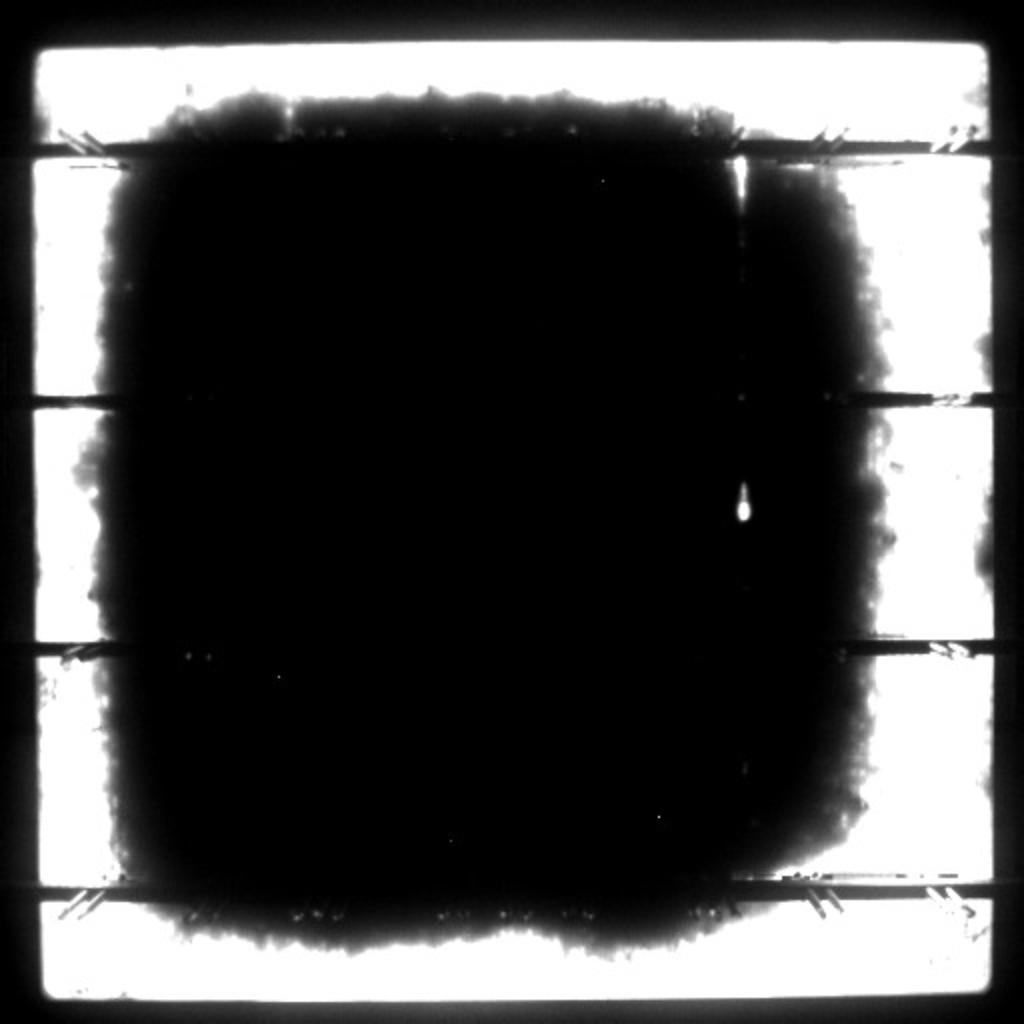

In [ ]:
# ============================================================
# Prepare Test Image for Final Streamlit UI
# ============================================================

import os
import shutil
from PIL import Image
from IPython.display import display

# Genuine untouched TEST-set image
# Block 14 confirmed:
# Ground truth = black_core
# Prediction   = black_core

SOURCE_IMAGE = (
    "/content/pv_final_project/data/processed/"
    "PVEL_AD_FINAL/images/test/"
    "img000007.jpg"
)

TEST_IMAGE = "/content/solar_test_image.jpg"

assert os.path.exists(SOURCE_IMAGE), \
    "Final test image not found."

shutil.copy2(
    SOURCE_IMAGE,
    TEST_IMAGE
)

print("✓ Test image prepared from untouched test set")

display(
    Image.open(TEST_IMAGE)
)


In [ ]:
from google.colab import files

files.download(
    "/content/solar_test_image.jpg"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>